
#Step 1. Rainfall data import, 1-min conversion by mass-conserving cumulative PCHIP, and plotting of all rainfall events
This notebook is the first step of the hydrological workflow for journal publication and Zenodo archiving.

＃Purpose
1. Read 10-min rainfall data from rain.xlsx.
2. Treat the first row of the Excel sheet as column headers (rainfall event names).
3. Convert each 10-min rainfall hyetograph to a 1-min hyetograph using mass-conserving cumulative PCHIP (Piecewise Cubic Hermite Interpolating Polynomial).
4. Make sure that rainfall depth is conserved for every 10-min block.
5. Plot all rainfall events in the file as a multi-panel figure.

＃Input
- rain.xlsx: 10-min rainfall depth time series (mm / 10 min)
- Each column name is a rainfall event name and can be used to call that rainfall event later.

＃Output
- rainfall_1min_mm_per_min.csv: 1-min rainfall depth series (mm / min)
- rainfall_1min_mm_per_h.csv: 1-min rainfall intensity (mm / h)
- rainfall_conservation_report.csv: conservation check for every rainfall event
- all_rainfall_events_1min_cumulative_PCHIP.png / .pdf: multi-panel figure of all rainfall events

In [34]:
# 1. Imports and configuration


# Standard imports
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# Figure style for publication-oriented plotting
plt.rcParams["font.family"] = ( "Arial" if "Arial" in available_fonts else "DejaVu Sans")
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['legend.fontsize'] = 9
plt.rcParams['figure.dpi'] = 120



# ---------------------------------------------------------------------
# User settings
# ---------------------------------------------------------------------
from google.colab import files

uploaded = files.upload()
INPUT_FILE = Path(next(iter(uploaded)))
OUTPUT_DIR = Path('rainfall_outputs_all_events')
OUTPUT_DIR.mkdir(exist_ok=True)

# If None, all rainfall events are plotted.
# You can also specify a subset such as ['2023', '2024', '2025'].
PLOT_NAMES = None

# If you only want columns whose names look like a year (e.g., 2006-2025),
# change this to True. Default is False because the present request is to
# plot all rainfall events in the file.
ONLY_FOUR_DIGIT_YEAR_COLUMNS = False


Saving rain.xlsx to rain (2).xlsx


In [35]:
# 2. Reusable functions


# ---------------------------------------------------------------------
# Functions
# ---------------------------------------------------------------------

def load_rainfall_table(filepath):
    """Read rainfall table from Excel and convert all column names to strings."""
    df = pd.read_excel(filepath)
    df.columns = [str(c) for c in df.columns]
    return df


def select_rainfall_names(df, plot_names=None, only_year_columns=False):
    """Return rainfall-event names to be processed/plotted."""
    names = [str(c) for c in df.columns]

    if only_year_columns:
        names = [n for n in names if len(n) == 4 and n.isdigit()]

    if plot_names is None:
        return names

    missing = [str(n) for n in plot_names if str(n) not in names]
    if missing:
        raise ValueError(f'Rainfall names not found in the file: {missing}')

    return [str(n) for n in plot_names]


def convert_10min_to_1min_mass_conserving_pchip(rain_10min_mm):
    """
    Convert 10-min rainfall depth (mm / 10 min) to 1-min rainfall depth
    (mm / min) using cumulative rainfall + PCHIP interpolation.

    Method:
    1. Build cumulative rainfall at 10-min nodes.
    2. Apply PCHIP to the cumulative rainfall.
    3. Evaluate at 1-min resolution.
    4. Take 1-min differences to get rainfall depth per minute.

    This approach conserves rainfall depth over each 10-min interval
    up to machine precision.
    """
    rain_10min_mm = np.asarray(rain_10min_mm, dtype=float)
    rain_10min_mm = np.nan_to_num(rain_10min_mm, nan=0.0)

    n = len(rain_10min_mm)
    t_10 = np.arange(0, (n + 1) * 10, 10, dtype=float)   # 0, 10, 20, ..., 10n
    cum_10 = np.concatenate(([0.0], np.cumsum(rain_10min_mm)))

    pchip = PchipInterpolator(t_10, cum_10)

    t_1 = np.arange(0, n * 10 + 1, 1, dtype=float)       # 0, 1, 2, ..., 10n
    cum_1 = pchip(t_1)

    # Numerical safety: cumulative rainfall should not decrease.
    cum_1 = np.maximum.accumulate(cum_1)

    rain_1min_mm = np.diff(cum_1)                        # mm / min
    rain_1min_mm = np.clip(rain_1min_mm, 0.0, None)

    return t_1[:-1], rain_1min_mm, cum_1


def check_10min_mass_conservation(rain_10min_mm, rain_1min_mm):
    """Check conservation over each 10-min block."""
    rain_10min_mm = np.asarray(rain_10min_mm, dtype=float)
    rain_10min_mm = np.nan_to_num(rain_10min_mm, nan=0.0)
    rain_1min_mm = np.asarray(rain_1min_mm, dtype=float)

    reconstructed = rain_1min_mm.reshape(-1, 10).sum(axis=1)
    errors = reconstructed - rain_10min_mm

    return {
        'max_abs_error_mm': float(np.max(np.abs(errors))),
        'mean_abs_error_mm': float(np.mean(np.abs(errors))),
        'total_input_mm': float(rain_10min_mm.sum()),
        'total_output_mm': float(rain_1min_mm.sum()),
        'total_error_mm': float(rain_1min_mm.sum() - rain_10min_mm.sum())
    }


def process_all_rainfall_events(df, names):
    """Convert all selected rainfall events and build outputs."""
    rain_1min_mm_dict = {}
    rain_1min_mmh_dict = {}
    conservation_records = []

    for name in names:
        rain_10 = df[name].fillna(0.0).to_numpy(dtype=float)
        t_1, rain_1min_mm, cum_1 = convert_10min_to_1min_mass_conserving_pchip(rain_10)
        report = check_10min_mass_conservation(rain_10, rain_1min_mm)
        report['name'] = name
        report['n_10min'] = len(rain_10)
        report['n_1min'] = len(rain_1min_mm)

        rain_1min_mm_dict[name] = rain_1min_mm
        rain_1min_mmh_dict[name] = rain_1min_mm * 60.0
        conservation_records.append(report)

    rain_1min_mm_df = pd.DataFrame(rain_1min_mm_dict)
    rain_1min_mmh_df = pd.DataFrame(rain_1min_mmh_dict)
    conservation_df = pd.DataFrame(conservation_records)

    return t_1, rain_1min_mm_df, rain_1min_mmh_df, conservation_df


def plot_all_rainfall_events(rain_1min_mm_df, title, output_png, output_pdf):
    """Plot all rainfall events as a multi-panel figure."""
    names = list(rain_1min_mm_df.columns)
    n = len(names)
    ncols = 4
    nrows = math.ceil(n / ncols)

    fig, axes = plt.subplots(nrows, ncols, figsize=(4.6 * ncols, 2.9 * nrows), sharex=True)
    axes = np.atleast_1d(axes).ravel()

    time = np.arange(len(rain_1min_mm_df))

    for ax, name in zip(axes, names):
        ax.plot(time, rain_1min_mm_df[name], linewidth=1.0)
        ax.set_title(str(name))
        ax.set_xlabel('Minutes')
        ax.set_ylabel('Rainfall (mm/min)')
        ax.grid(True, alpha=0.3)

    for ax in axes[n:]:
        ax.axis('off')

    fig.suptitle(title, fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(output_png, dpi=300, bbox_inches='tight')
    fig.savefig(output_pdf, bbox_inches='tight')
    plt.show()


In [36]:
# 3. Read and convert all rainfall events


# ---------------------------------------------------------------------
# Load data and determine rainfall names
# ---------------------------------------------------------------------
raw_df = load_rainfall_table(INPUT_FILE)
selected_names = select_rainfall_names(
    raw_df,
    plot_names=PLOT_NAMES,
    only_year_columns=ONLY_FOUR_DIGIT_YEAR_COLUMNS
)

print(f'Input file: {INPUT_FILE}')
print(f'Number of rainfall events selected: {len(selected_names)}')
print('Rainfall event names:')
print(selected_names)



# ---------------------------------------------------------------------
# Convert all rainfall events to 1-min rainfall
# ---------------------------------------------------------------------
minutes, rain_1min_mm_df, rain_1min_mmh_df, conservation_df = process_all_rainfall_events(raw_df, selected_names)

print('Shape of 1-min rainfall table (mm/min):', rain_1min_mm_df.shape)
print('Maximum absolute 10-min conservation error (mm):', conservation_df['max_abs_error_mm'].max())

conservation_df.head()


Input file: rain (2).xlsx
Number of rainfall events selected: 22
Rainfall event names:
['RT', 'RY', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
Shape of 1-min rainfall table (mm/min): (1440, 22)
Maximum absolute 10-min conservation error (mm): 1.4210854715202004e-14


,max_abs_error_mm,mean_abs_error_mm,total_input_mm,total_output_mm,total_error_mm,name,n_10min,n_1min
0,1.421085e-14,4.311366e-15,251.79,251.79,5.684342e-14,RT,144,1440
1,0.000000e+00,0.000000e+00,389.00,389.00,0.000000e+00,RY,144,1440
2,0.000000e+00,0.000000e+00,92.50,92.50,0.000000e+00,2006,144,1440
3,5.551115e-17,3.854941e-19,139.00,139.00,0.000000e+00,2007,144,1440
4,0.000000e+00,0.000000e+00,102.00,102.00,0.000000e+00,2008,144,1440


Saved:
rainfall_outputs_all_events/rainfall_1min_mm_per_min.csv
rainfall_outputs_all_events/rainfall_1min_mm_per_h.csv
rainfall_outputs_all_events/rainfall_conservation_report.csv


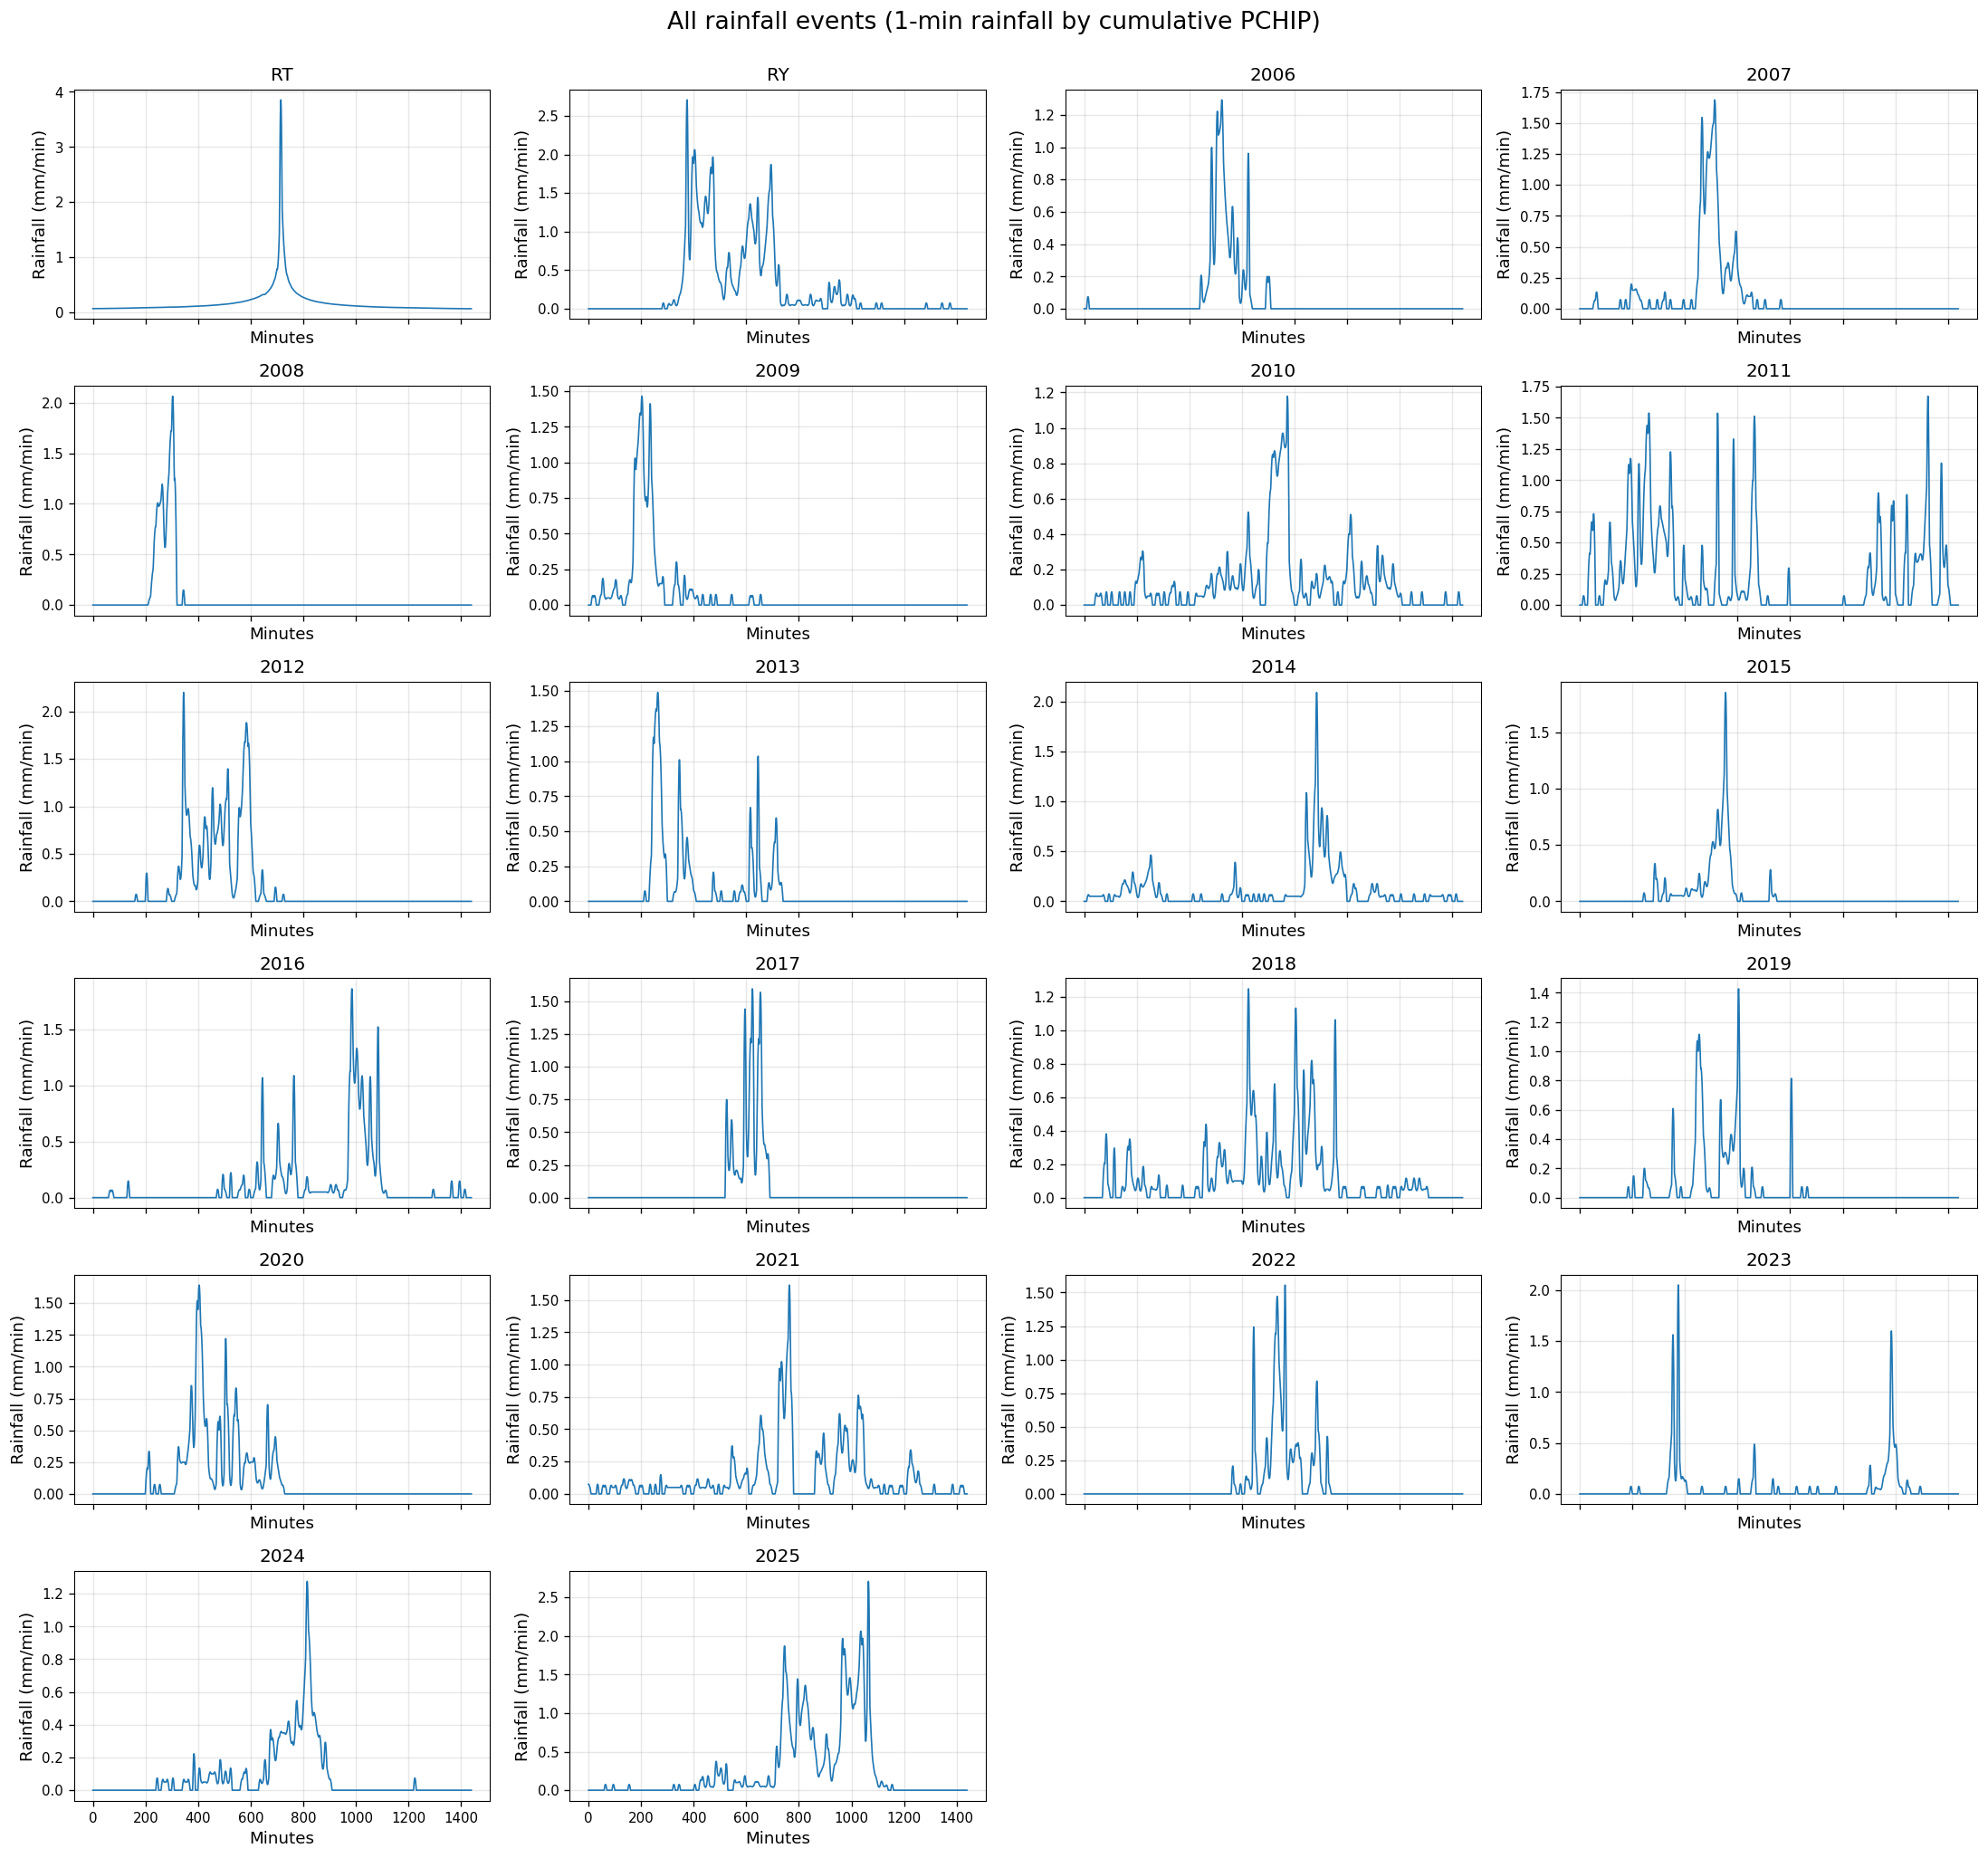

Saved figure files:
rainfall_outputs_all_events/all_rainfall_events_1min_cumulative_PCHIP.png
rainfall_outputs_all_events/all_rainfall_events_1min_cumulative_PCHIP.pdf
Example rainfall name: RT
Length of 1-min rainfall series: 1440
Total rainfall depth (mm): 251.790000


In [37]:
# 4. Save, plot and access rainfall by name


# ---------------------------------------------------------------------
# Save outputs
# ---------------------------------------------------------------------
rain_1min_mm_file = OUTPUT_DIR / 'rainfall_1min_mm_per_min.csv'
rain_1min_mmh_file = OUTPUT_DIR / 'rainfall_1min_mm_per_h.csv'
conservation_file = OUTPUT_DIR / 'rainfall_conservation_report.csv'
figure_png = OUTPUT_DIR / 'all_rainfall_events_1min_cumulative_PCHIP.png'
figure_pdf = OUTPUT_DIR / 'all_rainfall_events_1min_cumulative_PCHIP.pdf'

rain_1min_mm_df.to_csv(rain_1min_mm_file, index=False)
rain_1min_mmh_df.to_csv(rain_1min_mmh_file, index=False)
conservation_df.to_csv(conservation_file, index=False)

print('Saved:')
print(rain_1min_mm_file)
print(rain_1min_mmh_file)
print(conservation_file)



# ---------------------------------------------------------------------
# Plot all rainfall events
# ---------------------------------------------------------------------
plot_all_rainfall_events(
    rain_1min_mm_df,
    title='All rainfall events (1-min rainfall by cumulative PCHIP)',
    output_png=figure_png,
    output_pdf=figure_pdf,
)

print('Saved figure files:')
print(figure_png)
print(figure_pdf)



# ---------------------------------------------------------------------
# Example: call one rainfall event by name for later analyses
# ---------------------------------------------------------------------

def get_rainfall(name, unit='mm/min'):
    """Return one rainfall event by name."""
    name = str(name)
    if unit == 'mm/min':
        return rain_1min_mm_df[name].to_numpy()
    elif unit == 'mm/h':
        return rain_1min_mmh_df[name].to_numpy()
    else:
        raise ValueError("unit must be either 'mm/min' or 'mm/h'")

# Example
example_name = selected_names[0]
example_wave = get_rainfall(example_name, unit='mm/min')
print(f'Example rainfall name: {example_name}')
print(f'Length of 1-min rainfall series: {len(example_wave)}')
print(f'Total rainfall depth (mm): {example_wave.sum():.6f}')


#Step 2 — Rainfall density envelope curves
This notebook reads the 1-minute rainfall depths (mm/min) exported by Step 1. For each rainfall event and each window width w (minutes), it shifts the window endpoint through every valid minute and calculates the largest window-average rainfall intensity:

E(w) = (60 / w) max_t [ C(t) - C(t-w) ]  (mm/h), where C is cumulative rainfall depth (mm).

The units are rainfall intensity (mm/h); these curves are not observed runoff depths. Each panel uses the same event order and multi-panel style as Step 1. The complete envelope data are saved to CSV for later analyses. No smoothing or interpolation of the envelope curve is performed; values are evaluated at every integer window width.

Usage: Run Step 1 first so that rainfall_outputs_all_events/rainfall_1min_mm_per_min.csv exists alongside this notebook. Then run all four code cells below. Columns retain their event names (RT, RY, RYR, 2006–2025).

Events: 22, window widths: 1440, duration: 1440 min
Event names: ['RT', 'RY', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025']
1-minute envelope check: passed
                 RT       RY    2006     2007     2008
window_min                                            
1           231.321  162.520  77.577  101.235  123.895
2           230.025  162.356  77.495  100.990  123.772
3           227.887  159.990  77.182  100.680  122.968
4           224.875  158.561  76.903  100.157  122.380
5           221.019  154.931  76.392   99.569  121.112


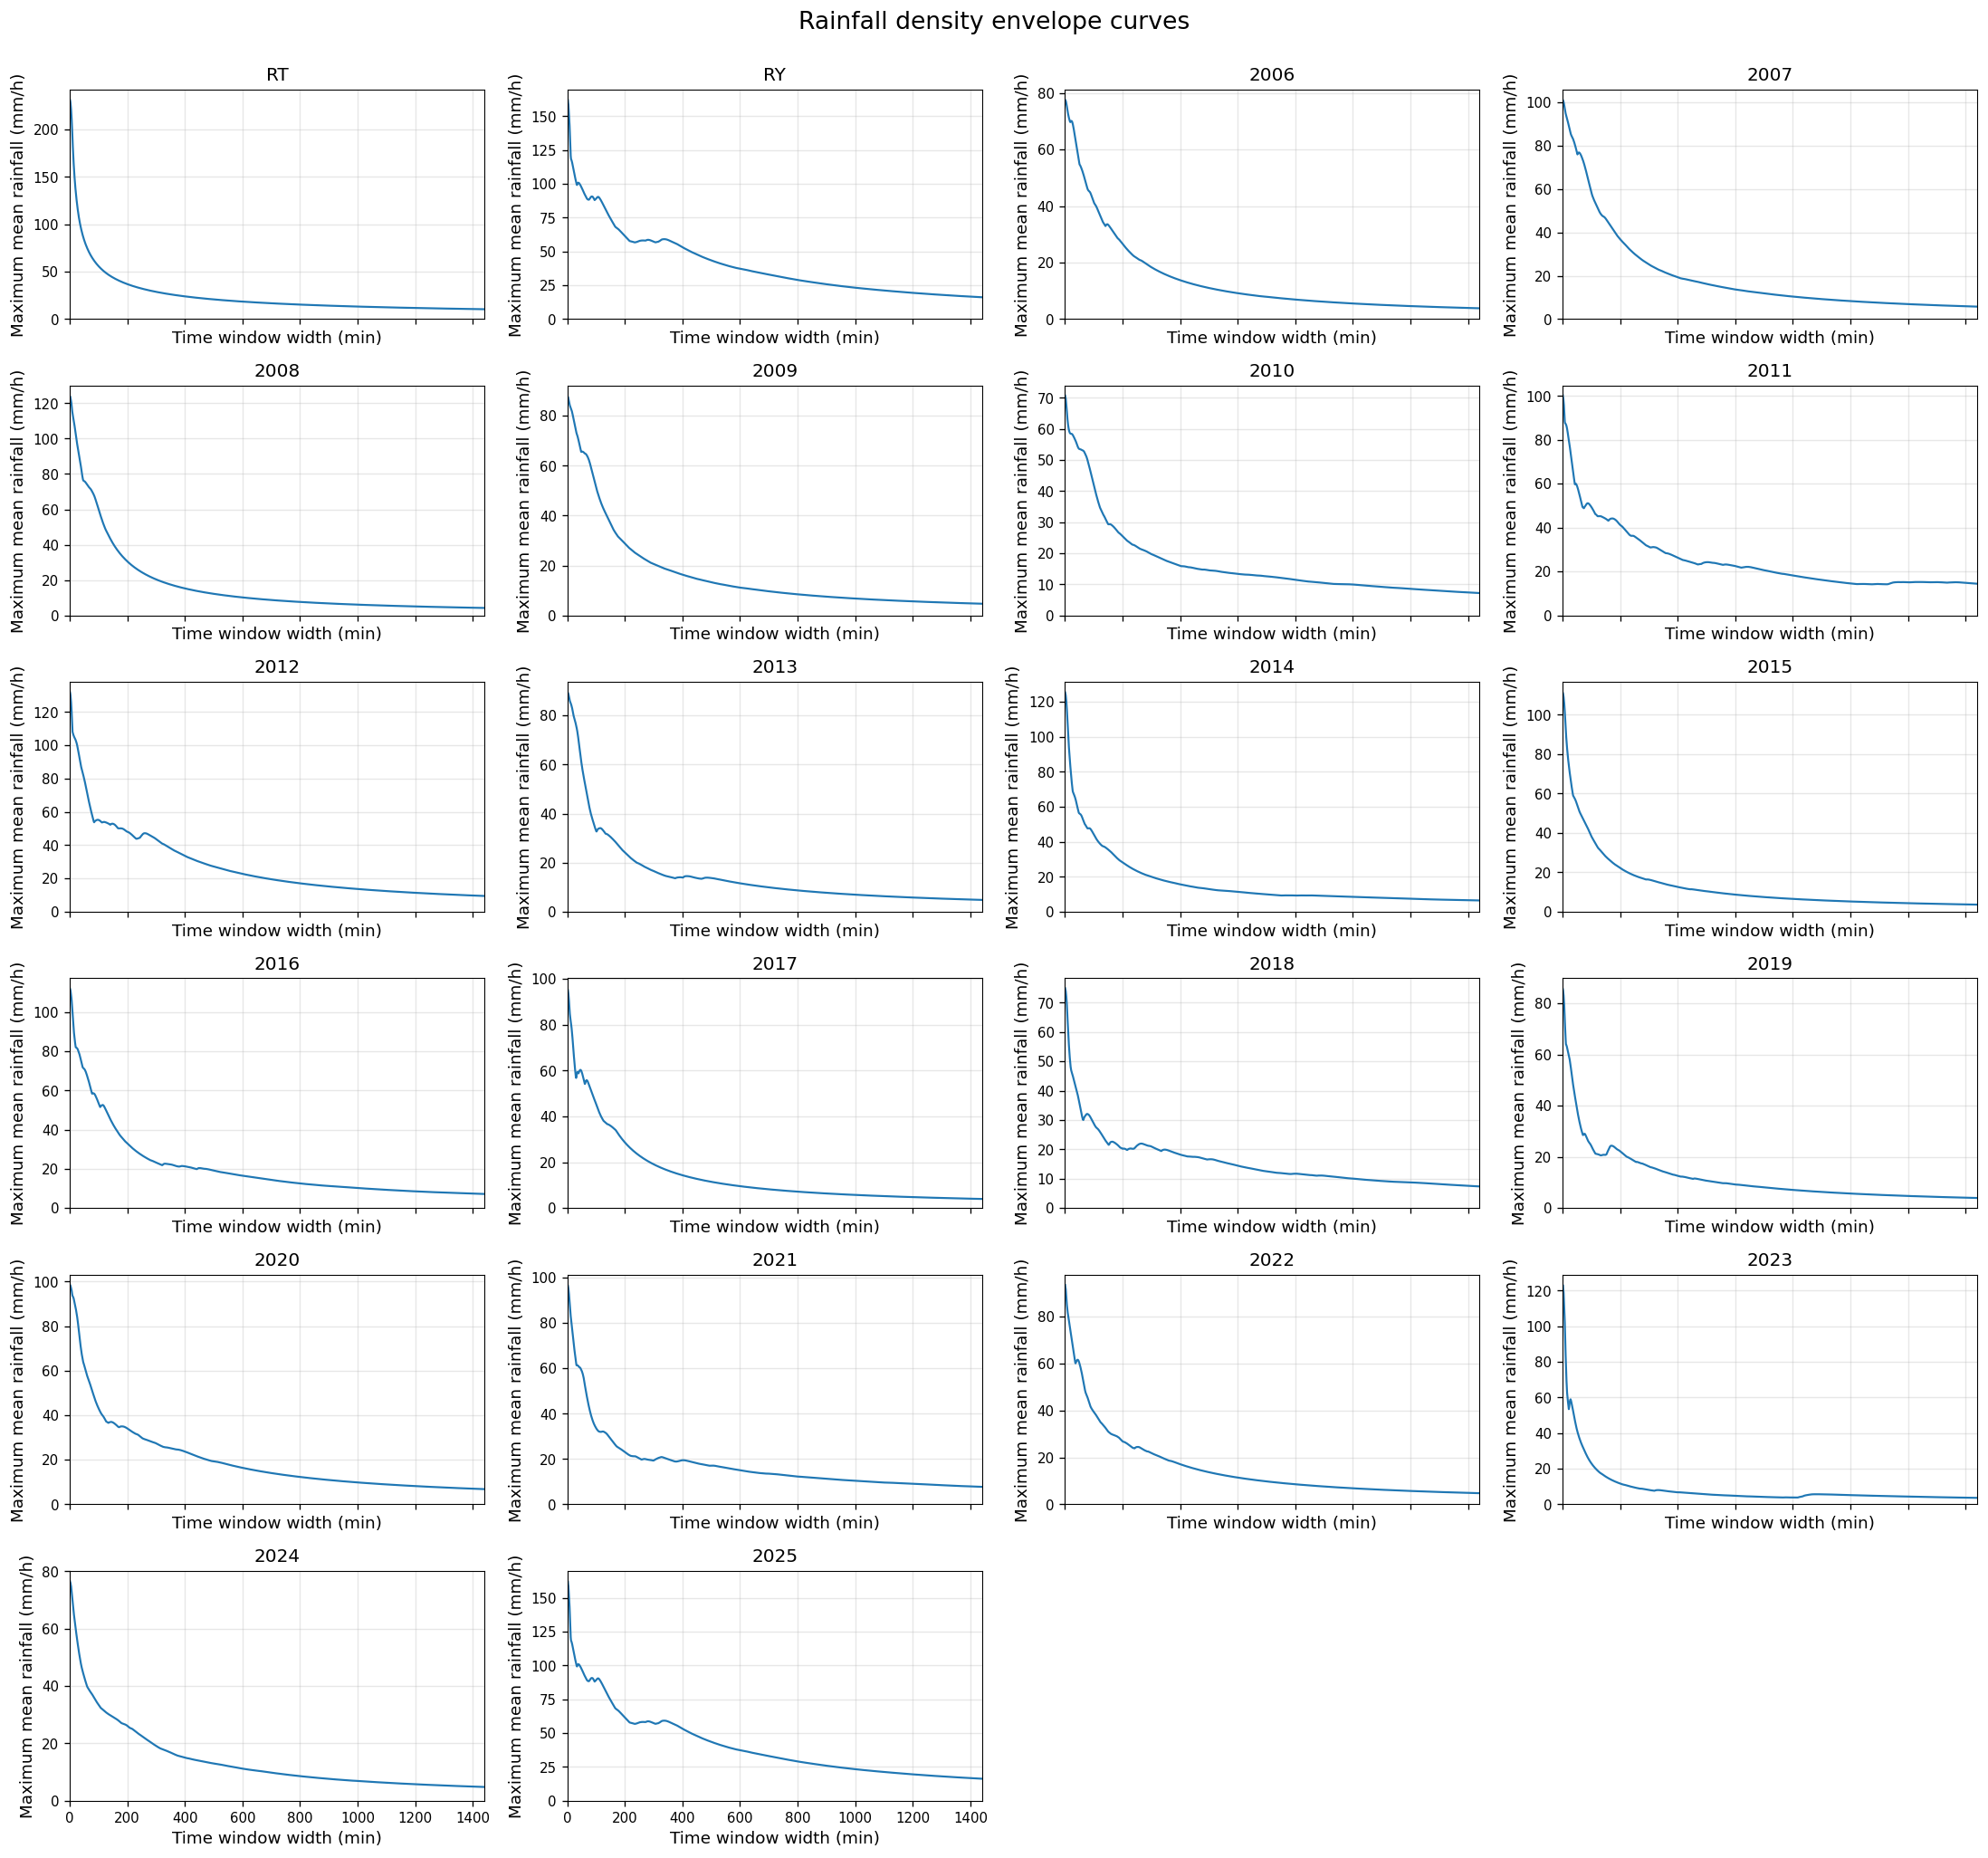

Saved:
  envelope_outputs_all_events/rainfall_density_envelopes_mm_per_h.csv
  envelope_outputs_all_events/envelope_peak_window_end_minutes.csv
  envelope_outputs_all_events/rainfall_density_envelopes_long.csv
  envelope_outputs_all_events/rainfall_density_envelopes_all_events.png
  envelope_outputs_all_events/rainfall_density_envelopes_all_events.pdf


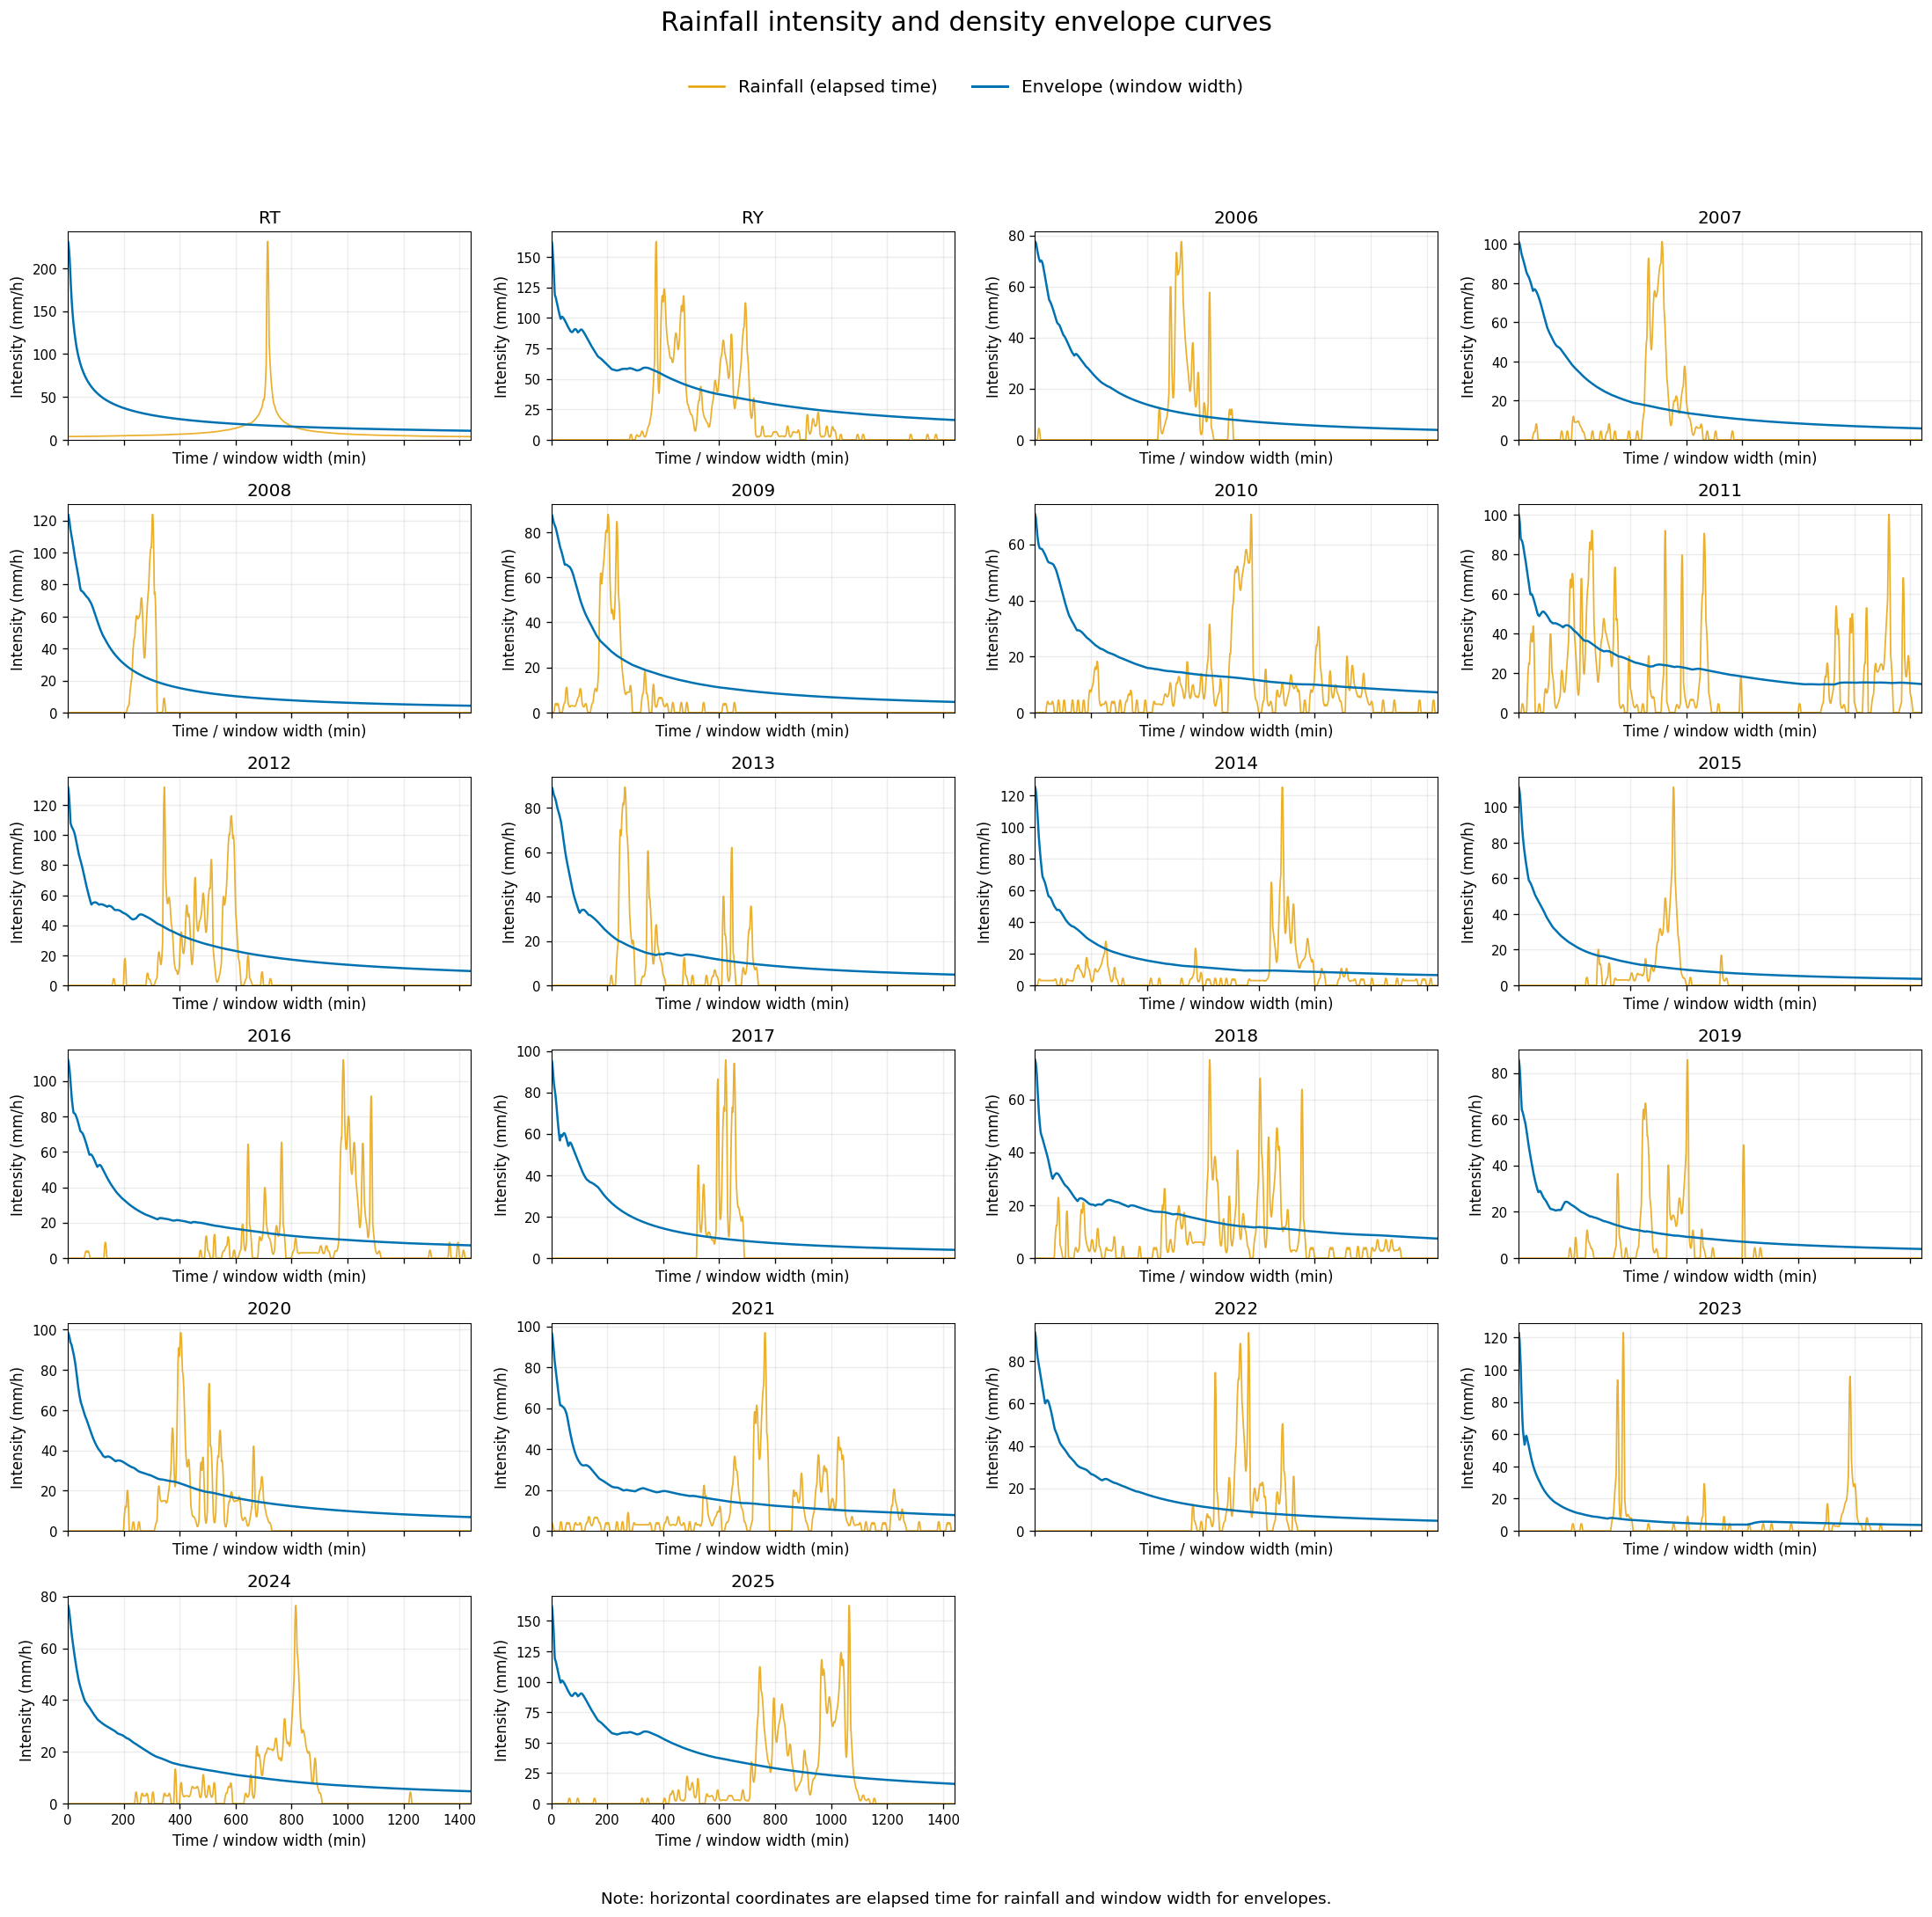

Saved:
envelope_outputs_all_events/rainfall_and_envelopes_overlay_all_events.png
envelope_outputs_all_events/rainfall_and_envelopes_overlay_all_events.pdf


In [59]:
# Step 2 — Envelopes and rainfall overlay (combined Step 2 cells only)

# 1. Imports and settings
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

INPUT_FILE = Path('rainfall_outputs_all_events/rainfall_1min_mm_per_min.csv')
OUTPUT_DIR = Path('envelope_outputs_all_events')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# None = every window width from 1 to the full record duration (1-min increments).
MAX_WINDOW_MIN = None

# No fixed list: use every rainfall event in the Step 1 CSV.
# If you later want a subset, specify e.g. ['2023', '2024'].
EVENT_NAMES = None

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = 'Arial' if 'Arial' in available_fonts else 'DejaVu Sans'
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['xtick.labelsize'] = 9
plt.rcParams['ytick.labelsize'] = 9
plt.rcParams['figure.dpi'] = 120


# 2. Calculation and plotting functions

def calculate_envelope(rain_mm_per_min, max_window_min=None):
    """Maximum moving-window mean intensity (mm/h), for all integer widths.

    Each endpoint t runs over w, ..., N. The last valid endpoint is included.
    Zero padding beyond the recorded period is never used.
    """
    rain = np.asarray(rain_mm_per_min, dtype=float)
    if rain.ndim != 1 or rain.size == 0 or not np.all(np.isfinite(rain)):
        raise ValueError('Rainfall data must be a non-empty, finite 1-D array.')
    if np.any(rain < -1e-10):
        raise ValueError('Negative rainfall encountered.')
    n = len(rain)
    max_w = n if max_window_min is None else int(max_window_min)
    if not 1 <= max_w <= n:
        raise ValueError(f'MAX_WINDOW_MIN must be between 1 and {n}.')
    cumulative = np.concatenate(([0.0], np.cumsum(rain)))
    windows = np.arange(1, max_w + 1, dtype=int)
    envelope_mmh = np.empty(max_w, dtype=float)
    peak_end_min = np.empty(max_w, dtype=int)
    for idx, w in enumerate(windows):
        # Sum of rainfall in every window [t-w, t): C[t] - C[t-w]
        depths_mm = cumulative[w:] - cumulative[:-w]
        best = int(np.argmax(depths_mm))
        peak_end_min[idx] = best + w
        envelope_mmh[idx] = depths_mm[best] * 60.0 / w
    return windows, envelope_mmh, peak_end_min


def plot_envelopes(envelope_df, png_file, pdf_file):
    names = list(envelope_df.columns)
    widths = envelope_df.index.to_numpy()
    cols = 4
    rows = math.ceil(len(names) / cols)
    fig, axarr = plt.subplots(rows, cols, figsize=(4.6 * cols, 2.9 * rows), sharex=True)
    axes = np.atleast_1d(axarr).ravel()
    for ax, name in zip(axes, names):
        ax.plot(widths, envelope_df[name].to_numpy(), linewidth=1.3)
        ax.set_title(str(name))
        ax.set_xlabel('Time window width (min)')
        ax.set_ylabel('Maximum mean rainfall (mm/h)')
        ax.set_xlim(0, int(widths[-1]))
        ax.set_ylim(bottom=0)
        ax.grid(True, alpha=0.3)
    for ax in axes[len(names):]:
        ax.axis('off')
    fig.suptitle('Rainfall density envelope curves', fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.98])
    fig.savefig(png_file, dpi=300, bbox_inches='tight')
    fig.savefig(pdf_file, bbox_inches='tight')
    plt.show()


# 3. Load Step 1 output and calculate envelope curves
if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f'{INPUT_FILE} not found. Run Step 1 first, then put this notebook '
        'beside the rainfall_outputs_all_events directory.'
    )

rainfall_df = pd.read_csv(INPUT_FILE)
rainfall_df.columns = rainfall_df.columns.map(str)
if EVENT_NAMES is not None:
    names = [str(name) for name in EVENT_NAMES]
    unknown = sorted(set(names) - set(rainfall_df.columns))
    if unknown:
        raise KeyError(f'Unknown rainfall event names: {unknown}')
else:
    names = list(rainfall_df.columns)

records = {}
endpoint_records = {}
windows = None
for name in names:
    w, envelope_mmh, end_minutes = calculate_envelope(
        rainfall_df[name].to_numpy(dtype=float), MAX_WINDOW_MIN
    )
    windows = w
    records[name] = envelope_mmh
    endpoint_records[name] = end_minutes

envelope_df = pd.DataFrame(records, index=pd.Index(windows, name='window_min'))
endpoints_df = pd.DataFrame(endpoint_records, index=pd.Index(windows, name='window_min'))

# Verify the 1-min envelope equals the input's largest 1-min rainfall intensity.
for name in names:
    expected = rainfall_df[name].max() * 60.0
    assert np.isclose(envelope_df.loc[1, name], expected, rtol=1e-10, atol=1e-8), name

print(f'Events: {len(names)}, window widths: {len(windows)}, duration: {len(rainfall_df)} min')
print('Event names:', names)
print('1-minute envelope check: passed')
print(envelope_df.iloc[:5, :min(5, len(names))].round(3))


# 4. Save all numeric data and draw the multi-panel figure
# Wide CSV: rows = window width, columns = rainfall event names.
wide_csv = OUTPUT_DIR / 'rainfall_density_envelopes_mm_per_h.csv'
ends_csv = OUTPUT_DIR / 'envelope_peak_window_end_minutes.csv'
long_csv = OUTPUT_DIR / 'rainfall_density_envelopes_long.csv'
figure_png = OUTPUT_DIR / 'rainfall_density_envelopes_all_events.png'
figure_pdf = OUTPUT_DIR / 'rainfall_density_envelopes_all_events.pdf'

envelope_df.to_csv(wide_csv, float_format='%.12g')
endpoints_df.to_csv(ends_csv)
long_df = envelope_df.stack().rename('envelope_mm_per_h').reset_index()
long_df.columns = ['window_min', 'rainfall_name', 'envelope_mm_per_h']
long_df['peak_window_end_min'] = [
    int(endpoints_df.loc[w, name])
    for w, name in zip(long_df['window_min'], long_df['rainfall_name'])
]
long_df.to_csv(long_csv, index=False, float_format='%.12g')

# Easy access by name for later steps. Example: get_envelope('2023')
def get_envelope(name):
    return envelope_df[str(name)].to_numpy(copy=True)

plot_envelopes(envelope_df, figure_png, figure_pdf)
print('Saved:')
for path in [wide_csv, ends_csv, long_csv, figure_png, figure_pdf]:
    print(' ', path)


# Step 2 — Overlay rainfall hyetographs and density envelopes (display only)
# The original interpolation and envelope calculations are NOT modified.
# Both curves are shown in mm/h. Their horizontal coordinates have different meanings:
# rainfall = elapsed time, envelope = time-window width.

from matplotlib.lines import Line2D
from matplotlib import font_manager

font_names = {f.name for f in font_manager.fontManager.ttflist}
font_to_use = next((f for f in ['Meiryo', 'Yu Gothic', 'Arial', 'DejaVu Sans'] if f in font_names), 'DejaVu Sans')


def plot_rainfall_envelope_overlays(rainfall_df, envelope_df, output_dir):
    event_names = list(envelope_df.columns)
    missing = set(event_names) - set(rainfall_df.columns)
    if missing:
        raise ValueError(f'Rainfall records missing for: {sorted(missing)}')

    ncols = 4
    nrows = math.ceil(len(event_names) / ncols)
    fig, axs = plt.subplots(nrows, ncols, figsize=(4.6*ncols, 3.0*nrows),
                            sharex=True, squeeze=False)
    axes = axs.ravel()
    widths = envelope_df.index.to_numpy(dtype=float)
    time = np.arange(len(rainfall_df), dtype=float)  # interval start (min)

    for ax, name in zip(axes, event_names):
        rainfall_mmh = rainfall_df[name].to_numpy(dtype=float)*60.0
        env_mmh = envelope_df[name].to_numpy(dtype=float)
        ax.plot(time, rainfall_mmh, color='#E69F00', lw=1.05, alpha=0.82,
                label='Rainfall intensity')
        ax.plot(widths, env_mmh, color='#0072B2', lw=1.5,
                label='Density envelope')
        ax.set_title(str(name), fontsize=12)
        ax.set_xlim(0, max(float(time[-1]), float(widths[-1])))
        ax.set_ylim(bottom=0)
        ax.set_xlabel('Time / window width (min)', fontsize=10)
        ax.set_ylabel('Intensity (mm/h)', fontsize=10)
        ax.tick_params(labelsize=9)
        ax.grid(alpha=0.24)

    for ax in axes[len(event_names):]:
        ax.axis('off')

    legend_items = [
        Line2D([0], [0], color='#E69F00', lw=1.5, label='Rainfall (elapsed time)'),
        Line2D([0], [0], color='#0072B2', lw=1.8, label='Envelope (window width)'),
    ]
    fig.legend(handles=legend_items, loc='upper center', ncol=2,
               bbox_to_anchor=(0.5, 0.972), frameon=False, fontsize=12)
    fig.suptitle('Rainfall intensity and density envelope curves', fontsize=18, y=1.0)
    fig.text(0.5, 0.002,
             'Note: horizontal coordinates are elapsed time for rainfall and window width for envelopes.',
             ha='center', va='bottom', fontsize=11)
    fig.tight_layout(rect=[0, 0.024, 1, 0.925])
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    png = output_dir / 'rainfall_and_envelopes_overlay_all_events.png'
    pdf = output_dir / 'rainfall_and_envelopes_overlay_all_events.pdf'
    fig.savefig(png, dpi=300, bbox_inches='tight')
    fig.savefig(pdf, bbox_inches='tight')
    plt.show()
    return png, pdf

with plt.rc_context({'font.family': font_to_use, 'pdf.fonttype': 42}):
    overlay_png, overlay_pdf = plot_rainfall_envelope_overlays(
        rainfall_df, envelope_df, OUTPUT_DIR
    )
print('Saved:', overlay_png, overlay_pdf, sep='\n')


#Step 3 — Nested six-catchment convolution and time-spread comparison
This notebook evaluates RT and RY for three nested drainage areas (1.2, 7.2, and 43.2 km²) without changing the Step 1 rainfall interpolation or Step 2 envelope algorithm.
- 1.2 km²: six equal 0.2 km² subcatchments, equal delays 0, dt, 2dt, …, 5dt.
- 7.2 km²: six identical 1.2 km² units, each having the previously convolved dt=2 min output as its input unit hydrograph.
- 43.2 km²: six identical 7.2 km² units, each having the previously convolved dt=6 min output as its input unit hydrograph.
- At each level, dt varies from 1 to 40 min in integer steps. Each curve is the density envelope of the synchronous (dt=0 at the current level) unit waveform, not the delayed output.
- Peak runoff depth rate is the maximum of the time-shifted, area-weighted sum of the six unit rates (mm/h). No infiltration or attenuation is imposed.
- Two x coordinates are shown for each computed peak: 5dt and √12 σ, with σ the flow-volume-weighted standard deviation of the six arrival offsets. Equal-area and identical unit hydrographs imply equal runoff-volume weights. This σ excludes the within-unit hydrograph shape.
Important: 5dt is the range of six arrival offsets; √12σ = √35 dt for six equally weighted offsets, so they are not exactly equal. Points with x > 200 min are calculated and saved but omitted from the requested 0–200 min figure. The original rainfall depth is treated as runoff depth (100% runoff) only for this simplified timing experiment.

In [60]:

# Cell 1 — Imports and settings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

INPUT_FILE = Path('rainfall_outputs_all_events/rainfall_1min_mm_per_min.csv')
OUTPUT_DIR = Path('step3_convolution_outputs')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RAIN_NAMES = ['RT', 'RY']
DT_LIST = np.arange(1, 41, dtype=int)  # 1 .. 40 min
MAX_PLOT_WIDTH = 200
N_SUB = 6
PLOT_COLORS = {'RT':'#e69f00', 'RY':'#0072b2'}

# If running in Colab and the Step 1 CSV is not already present, upload it.
if not INPUT_FILE.exists():
    try:
        from google.colab import files
        print('Upload rainfall_1min_mm_per_min.csv from Step 1.')
        incoming = files.upload()
        if not incoming:
            raise FileNotFoundError('No CSV was uploaded.')
        INPUT_FILE = Path(next(iter(incoming)))
    except ImportError as exc:
        raise FileNotFoundError(
            'Step 1 output CSV not found. Place rainfall_1min_mm_per_min.csv '
            'in rainfall_outputs_all_events/ or change INPUT_FILE.'
        ) from exc

font_names = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams['font.family'] = 'Arial' if 'Arial' in font_names else 'DejaVu Sans'
plt.rcParams.update({'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.linewidth': 0.65,
                     'xtick.direction':'out', 'ytick.direction':'out'})
print('Input:', INPUT_FILE)


Input: rainfall_outputs_all_events/rainfall_1min_mm_per_min.csv


In [61]:

# Cell 2 — Numerical functions (no interpolation of the envelopes)
def shifted_aggregation(base_mm_per_min, dt_min, n_sub=6):
    """Area-weighted aggregate of n_sub equal-area hydrographs, 0..(n_sub-1)dt.
    Zero padding avoids periodic wrap-around and preserves the total depth.
    Output represents runoff depth per minute averaged over TOTAL area.
    """
    base = np.asarray(base_mm_per_min, dtype=float)
    if np.any(~np.isfinite(base)) or np.any(base < 0):
        raise ValueError('Input depths must be finite and nonnegative.')
    dt_min = int(dt_min)
    result = np.zeros(len(base) + (n_sub - 1) * dt_min, dtype=float)
    for i in range(n_sub):
        result[i*dt_min:i*dt_min+len(base)] += base / n_sub
    return result


def density_envelope(base_mm_per_min, max_width=200):
    """Maximum moving-window mean (mm/h) over each integer-width window."""
    base = np.asarray(base_mm_per_min, dtype=float)
    cum = np.r_[0.0, np.cumsum(base)]
    widths = np.arange(1, min(max_width, len(base)) + 1)
    values = np.array([60.0 * np.max(cum[w:] - cum[:-w]) / w for w in widths])
    return widths, values


def arrival_spread(dt_min, n_sub=6, volumes=None):
    """Volume-weighted σ of component arrival OFFSETS, not waveform-time σ."""
    delays = np.arange(n_sub, dtype=float) * dt_min
    weights = np.ones(n_sub) if volumes is None else np.asarray(volumes, dtype=float)
    weights = weights / weights.sum()
    mean = np.dot(weights, delays)
    sigma = np.sqrt(np.dot(weights, (delays - mean) ** 2))
    return 5.0*dt_min, np.sqrt(12.0)*sigma, sigma


def build_results(data):
    """Returns envelope table, peak table, and input waveforms for all 3 scales."""
    curves, peaks, waveforms = [], [], {}
    for rain_name in RAIN_NAMES:
        if rain_name not in data.columns:
            raise KeyError(f'Rainfall event {rain_name!r} was not found in the CSV.')
        rain = data[rain_name].to_numpy(dtype=float)
        if np.any(np.isnan(rain)):
            raise ValueError(f'NaN found in rainfall {rain_name}.')

        # Hierarchical input waveforms, with FIXED lower-level reference dt values.
        unit_1 = rain
        unit_2 = shifted_aggregation(unit_1, 2, N_SUB)
        unit_3 = shifted_aggregation(unit_2, 6, N_SUB)

        for area, unit, reference_dt in [(1.2, unit_1, 0), (7.2, unit_2, 2),
                                         (43.2, unit_3, 6)]:
            waveforms[(rain_name, area)] = unit
            widths, envelope = density_envelope(unit, MAX_PLOT_WIDTH)
            for w, rho in zip(widths, envelope):
                curves.append({'rainfall':rain_name, 'area_km2':area,
                               'window_min':int(w), 'envelope_mm_h':float(rho),
                               'input_reference_dt_min':reference_dt})

            for dt in DT_LIST:
                convolved = shifted_aggregation(unit, dt, N_SUB)
                peak = float(60.0 * convolved.max())
                width_5dt, width_sigma, sigma = arrival_spread(dt, N_SUB)
                peaks.append({'rainfall':rain_name, 'area_km2':area,
                              'dt_min':int(dt), 'x_5dt_min':width_5dt,
                              'x_sqrt12_sigma_min':width_sigma,
                              'sigma_arrival_min':sigma,
                              'peak_runoff_mm_h':peak,
                              'input_reference_dt_min':reference_dt,
                              'volume_input_mm':unit.sum(),
                              'volume_output_mm':convolved.sum()})
    return pd.DataFrame(curves), pd.DataFrame(peaks), waveforms


In [62]:

# Cell 3 — Read Step 1 data; build all results and verify mass conservation
rainfall_data = pd.read_csv(INPUT_FILE)
rainfall_data.columns = rainfall_data.columns.astype(str)
envelope_df, peak_df, base_waveforms = build_results(rainfall_data)

mass_error = (peak_df['volume_output_mm'] - peak_df['volume_input_mm']).abs().max()
assert mass_error < 1e-8, f'Mass conservation failed: {mass_error}'
assert np.allclose(peak_df['x_sqrt12_sigma_min'], np.sqrt(35) * peak_df['dt_min'])
print('Areas:', sorted(peak_df.area_km2.unique()))
print('Rainfall names:', RAIN_NAMES)
print('Maximum absolute runoff-depth conservation error (mm):', mass_error)
print('Rows: envelopes =', len(envelope_df), ', peaks =', len(peak_df))

# Keep all dt results, including points beyond the 200-min plot boundary.
envelope_df.to_csv(OUTPUT_DIR / 'envelopes_by_rainfall_and_area.csv', index=False)
peak_df.to_csv(OUTPUT_DIR / 'convolution_peak_and_spread.csv', index=False)
for name in RAIN_NAMES:
    wide = (envelope_df[envelope_df.rainfall == name]
            .pivot(index='window_min', columns='area_km2', values='envelope_mm_h'))
    wide.to_csv(OUTPUT_DIR / f'envelopes_{name}_wide.csv')


Areas: [np.float64(1.2), np.float64(7.2), np.float64(43.2)]
Rainfall names: ['RT', 'RY']
Maximum absolute runoff-depth conservation error (mm): 5.684341886080802e-14
Rows: envelopes = 1200 , peaks = 240


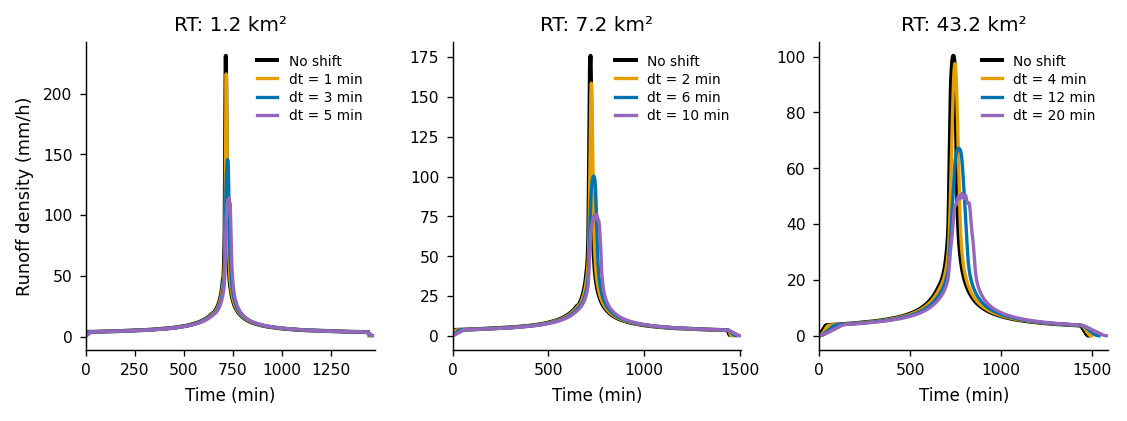

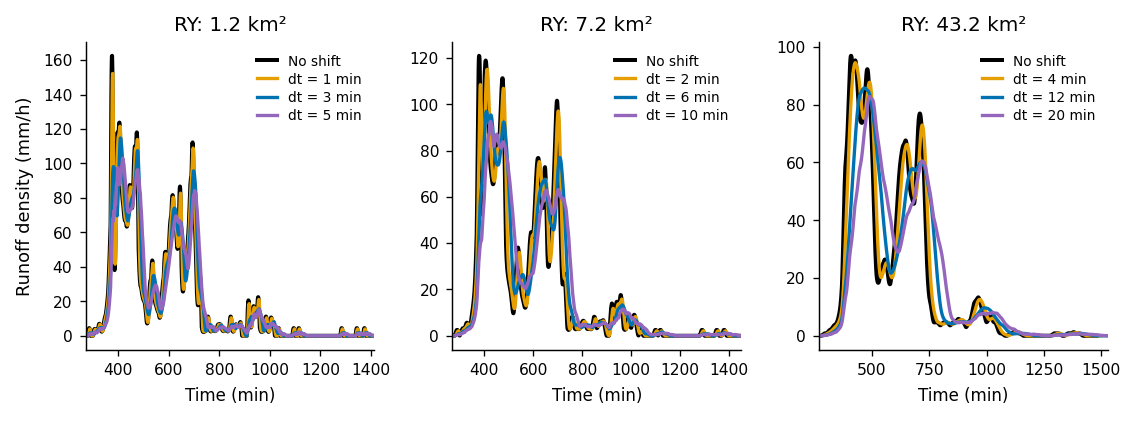

Hydrograph figures saved in: step3_convolution_outputs


In [63]:

# ============================================================
# Cell 4 — Combined runoff hydrographs at three watershed scales
# RT and RY / Nature Portfolio figure
# ============================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. Time shifts for each watershed scale (min)
# ------------------------------------------------------------

SELECTED_DTS = {
    1.2:  [0, 1, 3, 5],
    7.2:  [0, 2, 6, 10],
    43.2: [0, 4, 12, 20],
}

# ------------------------------------------------------------
# 2. Colors and line styles
# ------------------------------------------------------------

LINE_COLORS = [
    "#000000",  # Black: no shift
    "#E69F00",  # Yellow: small dt
    "#0072B2",  # Blue: medium dt
    "#9467BD",  # Purple: large dt
]

LINE_STYLES = ["-", "-", "-", "-"]
LINE_WIDTHS = [1.8, 1.5, 1.5, 1.5]

# ------------------------------------------------------------
# 3. Time-axis range
# ------------------------------------------------------------

def get_time_range(curves, threshold=1e-6, margin=10):

    indices = []

    for y in curves:
        idx = np.where(y > threshold)[0]

        if len(idx) > 0:
            indices.extend([idx[0], idx[-1]])

    if not indices:
        return 0, 100

    xmin = max(0, min(indices) - margin)
    xmax = max(indices) + margin

    return xmin, xmax


# ------------------------------------------------------------
# 4. Plot RT and RY separately
# ------------------------------------------------------------

for rain_name in RAIN_NAMES:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(7.10, 2.75),
        dpi=160,
        sharey=False
    )

    for ax, area in zip(axes, [1.2, 7.2, 43.2]):

        base = base_waveforms[(rain_name, area)]
        dt_values = SELECTED_DTS[area]

        curves = []
        labels = []

        # Generate hydrographs
        for dt in dt_values:

            hydrograph = shifted_aggregation(
                base, dt, N_SUB
            )

            density = hydrograph * 60.0  # mm/h

            curves.append(density)

            if dt == 0:
                labels.append("No shift")
            else:
                labels.append(f"dt = {dt} min")

        xmin, xmax = get_time_range(curves)

        # Draw hydrographs
        for i, (y, label) in enumerate(zip(curves, labels)):

            ax.plot(
                np.arange(len(y)),
                y,
                color=LINE_COLORS[i],
                linestyle=LINE_STYLES[i],
                linewidth=LINE_WIDTHS[i],
                label=label
            )

        # Axis settings
        ax.set_title(
            f"{rain_name}: {area:g} km²",
            fontsize=9,
            pad=5
        )

        ax.set_xlim(xmin, xmax)

        ax.tick_params(
            labelsize=7,
            length=2.5,
            width=0.6
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

        ax.grid(False)

        ax.set_xlabel(
            "Time (min)",
            fontsize=7.5
        )

        # Individual legend for each watershed
        ax.legend(
            loc="upper right",
            fontsize=6.2,
            frameon=False,
            handlelength=1.5,
            labelspacing=0.3
        )

    axes[0].set_ylabel(
        "Runoff density (mm/h)",
        fontsize=8
    )

    # --------------------------------------------------------
    # 5. Layout
    # --------------------------------------------------------

    fig.subplots_adjust(
        left=0.09,
        right=0.99,
        bottom=0.18,
        top=0.88,
        wspace=0.27
    )

    # --------------------------------------------------------
    # 6. Save figures
    # --------------------------------------------------------

    filename = (
        f"{rain_name}_aggregated_hydrographs_"
        f"selected_dt_3panels"
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.png",
        dpi=600,
        bbox_inches="tight",
        pad_inches=0.04
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.pdf",
        bbox_inches="tight",
        pad_inches=0.04
    )

    fig.savefig(
        OUTPUT_DIR / f"{filename}.svg",
        bbox_inches="tight",
        pad_inches=0.04
    )

    plt.show()

print("Hydrograph figures saved in:", OUTPUT_DIR)


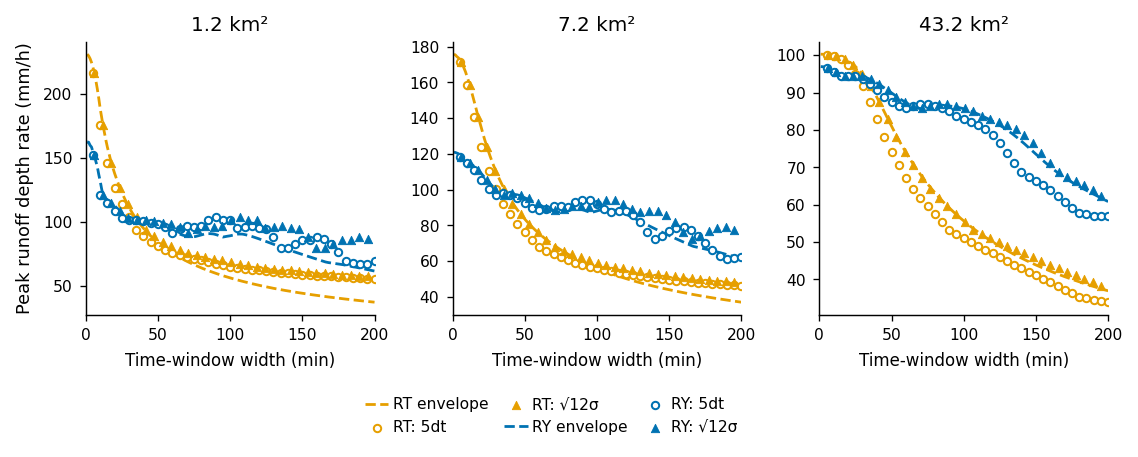

Saved plots and numeric CSV files in: step3_convolution_outputs


In [64]:

# Cell 5 — A4 portrait-compatible three-panel figure, plus high-resolution files
# Total width 7.1 in (180 mm). Three horizontal panels, compact labels/legend.
fig, axes = plt.subplots(1, 3, figsize=(7.10, 2.75), dpi=160,
                         sharex=True, sharey=False)
for ax, area in zip(axes, [1.2, 7.2, 43.2]):
    for rain_name in RAIN_NAMES:
        ec = envelope_df[(envelope_df.area_km2 == area) & (envelope_df.rainfall == rain_name)]
        pk = peak_df[(peak_df.area_km2 == area) & (peak_df.rainfall == rain_name)]
        color = PLOT_COLORS[rain_name]
        ax.plot(ec.window_min, ec.envelope_mm_h, ls='--', lw=1.25,
                color=color, label=f'{rain_name} envelope')
        subset5 = pk.loc[pk.x_5dt_min <= MAX_PLOT_WIDTH]
        subsets = pk.loc[pk.x_sqrt12_sigma_min <= MAX_PLOT_WIDTH]
        ax.scatter(subset5.x_5dt_min, subset5.peak_runoff_mm_h,
                   s=11, marker='o', facecolors='white', edgecolors=color,
                   linewidths=0.9, label=f'{rain_name}: 5dt', zorder=3)
        ax.scatter(subsets.x_sqrt12_sigma_min, subsets.peak_runoff_mm_h,
                   s=14, marker='^', color=color, linewidths=0.4,
                   label=f'{rain_name}: √12σ', zorder=3)
    ax.set_title(f'{area:g} km²', fontsize=9, pad=5)
    ax.set_xlim(0, MAX_PLOT_WIDTH)
    ax.set_xticks([0, 50, 100, 150, 200])
    ax.tick_params(labelsize=7, length=2.5, width=0.6)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(False)
    ax.set_xlabel('Time-window width (min)', fontsize=7.5)
axes[0].set_ylabel('Peak runoff depth rate (mm/h)', fontsize=8)

# One shared 2-row legend leaves plot area readable at journal column width.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, -0.045), frameon=False, fontsize=7,
           handlelength=1.5, columnspacing=1.0, handletextpad=0.3)
fig.subplots_adjust(left=0.09, right=0.99, bottom=0.26, top=0.88, wspace=0.27)
fig.savefig(OUTPUT_DIR / 'three_scales_A4_3panels.png', dpi=600,
            bbox_inches='tight', pad_inches=0.04)
fig.savefig(OUTPUT_DIR / 'three_scales_A4_3panels.pdf',
            bbox_inches='tight', pad_inches=0.04)
fig.savefig(OUTPUT_DIR / 'three_scales_A4_3panels.svg',
            bbox_inches='tight', pad_inches=0.04)
plt.show()

print('Saved plots and numeric CSV files in:', OUTPUT_DIR)


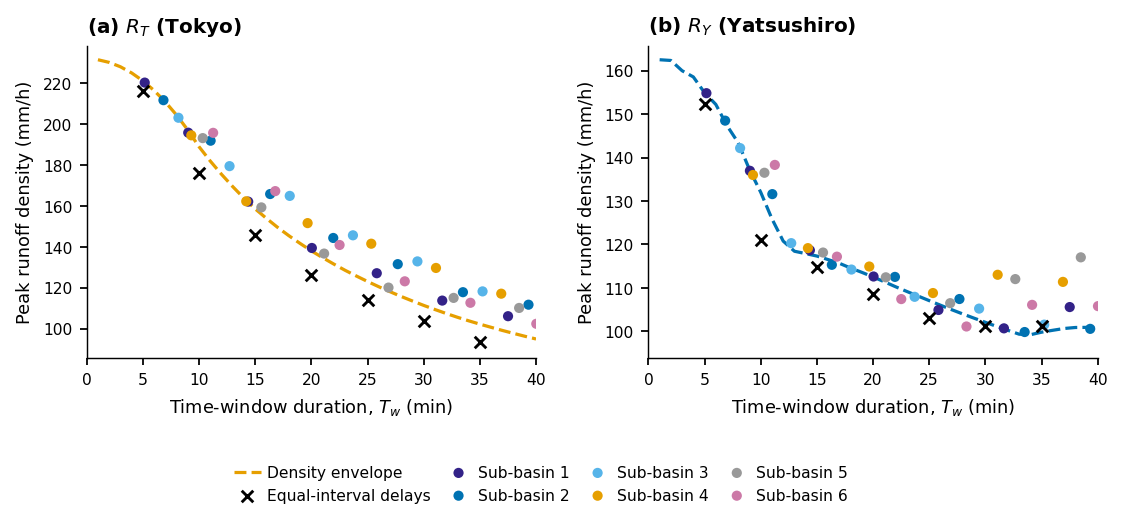

Saved figure and data to: step3_convolution_outputs


In [65]:
# ================================================================
# Cell 6 — Single-subcatchment additional 5-min delay (1.2 km²)
# Run after Step 3 Cells 1–3. No changes to existing functions.
# ================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

EXTRA_DELAY_MIN = 5
DT_VALUES = np.arange(1, 8, dtype=int)  # x = 5dt <= 35 min; plot up to 40 min
PLOT_X_MAX = 40
FIG_OUT = Path(OUTPUT_DIR)
FIG_OUT.mkdir(parents=True, exist_ok=True)

# Restricted palette: black, orange, blue, purple, and colorblind-friendly teal/gold.
POSITION_COLORS = ['#332288', '#0072B2', '#56B4E9', '#E69F00', '#999999', '#CC79A7']


def aggregate_one_extra_delay(base, dt, extra_position=None, extra=5, n=6):
    """Six equal-area series, initial offsets i*dt, plus optional extra offset.
    extra_position: 0..5 or None. No circular wrapping; depth conserved.
    Returns aggregate density depth (mm/min) and six arrival offsets (min).
    """
    base = np.asarray(base, dtype=float)
    delays = np.arange(n, dtype=int) * int(dt)
    if extra_position is not None:
        delays[int(extra_position)] += int(extra)
    result = np.zeros(len(base) + int(delays.max()), dtype=float)
    for d in delays:
        result[d:d + len(base)] += base / n
    return result, delays


def equivalent_window_from_delays(delays):
    """Volume-weighted spread; identical source volumes => equal weights."""
    delays = np.asarray(delays, float)
    weights = np.full(delays.size, 1 / delays.size)
    mean = np.dot(weights, delays)
    sigma = np.sqrt(np.dot(weights, (delays - mean) ** 2))
    return float(np.sqrt(12) * sigma)


results = []
for name in ['RT', 'RY']:
    # 0.2 km² source hydrograph: rainfall as 100% effective runoff.
    source = base_waveforms[(name, 1.2)]
    for dt in DT_VALUES:
        for pos in [None, *range(6)]:
            combined, delays = aggregate_one_extra_delay(
                source, dt, extra_position=pos, extra=EXTRA_DELAY_MIN, n=N_SUB
            )
            expected_depth = source.sum()
            if not np.isclose(combined.sum(), expected_depth, rtol=0, atol=1e-9):
                raise AssertionError('Volume conservation failed')
            results.append({
                'rainfall': name, 'area_km2': 1.2, 'dt_min': int(dt),
                'delayed_subcatchment': 0 if pos is None else int(pos + 1),
                'additional_delay_min': 0 if pos is None else EXTRA_DELAY_MIN,
                'x_5dt_baseline_min': float(5*dt),
                'x_sqrt12sigma_min': equivalent_window_from_delays(delays),
                'peak_density_mm_h': float(60 * combined.max()),
                'total_depth_mm': float(combined.sum())
            })

extra_delay_df = pd.DataFrame(results)
extra_delay_df.to_csv(FIG_OUT / 'single_subcatchment_extra5min_results.csv', index=False)

fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.15), dpi=160)
for ax, name, panel, env_color in zip(axes, ['RT', 'RY'], ['(a)', '(b)'], ['#E69F00', '#0072B2']):
    # Comparison envelope of unshifted source, same Step 3 calculation.
    source = base_waveforms[(name, 1.2)]
    widths, values = density_envelope(source, max_width=PLOT_X_MAX)
    ax.plot(widths, values, ls='--', lw=1.45, color=env_color, label='Density envelope')
    part = extra_delay_df.query('rainfall == @name')
    no_extra = part[part.delayed_subcatchment == 0]
    # The baseline is plotted at the geometric span 5dt, as in the reference figure.
    ax.scatter(no_extra.x_5dt_baseline_min, no_extra.peak_density_mm_h,
               marker='x', color='black', s=27, lw=1.3,
               label='Equal-interval delays', zorder=4)
    for k in range(1, 7):
        sel = part[part.delayed_subcatchment == k]
        ax.scatter(sel.x_sqrt12sigma_min, sel.peak_density_mm_h,
                   color=POSITION_COLORS[k-1], edgecolors='none', s=21,
                   label=f'Sub-basin {k}', zorder=3)
    ax.set_title(f'{panel} $R_{{{name[1:].lower()}}}$ ({"Tokyo" if name == "RT" else "Yatsushiro"})' if False else
                 (r'(a) $R_T$ (Tokyo)' if name == 'RT' else r'(b) $R_Y$ (Yatsushiro)'),
                 fontsize=9, loc='left', fontweight='bold')
    ax.set_xlim(0, PLOT_X_MAX)
    ax.set_xlabel(r'Time-window duration, $T_w$ (min)', fontsize=8)
    ax.set_ylabel('Peak runoff density (mm/h)', fontsize=8)
    ax.tick_params(labelsize=7, length=3)
    ax.spines[['top','right']].set_visible(False)
    ax.grid(False)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, fontsize=7,
           bbox_to_anchor=(0.5, -0.045), frameon=False,
           handletextpad=0.4, columnspacing=0.95, handlelength=1.7)
fig.subplots_adjust(left=0.10, right=0.99, top=0.89, bottom=0.27, wspace=0.25)
for extension in ['png','pdf','svg']:
    fig.savefig(FIG_OUT / f'single_subcatchment_extra5min.{extension}',
                dpi=600 if extension == 'png' else None,
                bbox_inches='tight', pad_inches=0.04)
plt.show()
print('Saved figure and data to:', FIG_OUT)


#Step 4 — GI placement equivalence: predicted versus achieved reduction
Scope (only two analyses). (A) Two density envelopes (no GI and with GI) with planning predictions at 5dt (black ×) and pre-GI √12σ₀ (black △), plus achieved GI peaks (colored ● plotted at post-GI flow-weighted √12σw); (B) location-wise mean prediction errors and variability over dt = 1–7 minutes (mean bars ± SD, with each dt shown as a point). RT and RY and infiltration / paddy are kept separate.

Definitions. A synchronized envelope is obtained from the six local source hydrographs averaged without inter-subcatchment offsets; it represents a common-window maximum moving mean. The baseline and GI envelopes are computed separately. For the six equal-area, equally spaced arrivals before GI, √12σ₀ = √35·dt (distinct from 5dt). Planning prediction: Δρ_pred(T) = E₀(T) − E_GI(T). Achieved reduction: Δρ_actual = ρmax,0 − ρmax,GI. Prediction error: ε = Δρ_actual − Δρ_pred(T). Positive ε means greater achieved reduction than predicted.

Existing physical model retained. 1.2 km² divided into 6 × 0.2 km²; infiltration 75 mm/h on 60% of one subcatchment versus 10% in each; paddy network 4 branches × (14 upstream + 2 middle + 1 downstream) = 68 paddies, 3000 m² each, rectangular bottom weir width 0.30 m, bund 0.30 m, 30-second transfer per tier. The previous provisional cyclic placement mapping [0,1,2,4] across six subcatchments is retained; these paddy positions are scenario labels rather than six single-branch placements. Unmodified areas generate 100% direct runoff. Initial paddy storage is zero.

The plotting x coordinate of the colored dots is the resulting flow-weighted time spread, whereas black prediction markers use the predefined planning windows. Do not interpret their horizontal displacement as prediction error. The comparison of planning accuracy is based on Δρ, not the vertical distance between offset markers. Baseline and GI envelopes are shared across positions only if the multiset of six source hydrographs is the same (true for this experiment).

In [73]:
# Step 4 — 1. Parameters and hydrologic functions (Step 1–3 unchanged)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

S4_DIR = Path('step4_spatial_equivalence_outputs')
S4_DIR.mkdir(parents=True, exist_ok=True)
S4_DTS = list(range(1, 8))
S4_RAIN = ['RT','RY']
N_S4 = 6
SUB_AREA_M2 = 200_000.0
INFILTRATION_MM_H = 75.0
PADDY_AREA_M2 = 3000.0
PADDY_WEIR_WIDTH_M = 0.30
PADDY_BUND_M = 0.30
PADDY_WEIR_COEFF = 1.70  # Q(m3/s) = C * B(m) * head(m)^(3/2)
PADDY_ROUTE_SECONDS = 30
PADDY_STEP_SECONDS = 30
BRANCH_SUBBASINS = [0,1,2,4]  # initial four branches; rotate around 6 possible subbasins

# Optional: use Meiryo when installed (publication figure typography)
from matplotlib import font_manager
if 'Meiryo' in {f.name for f in font_manager.fontManager.ttflist}:
    plt.rcParams['font.family'] = 'Meiryo'

def s4_infiltration_source(rain_mm_min, treated_share, infil_mm_h=75):
    rain = np.asarray(rain_mm_min, float)
    local_infil = np.minimum(rain, infil_mm_h / 60.0)
    return rain - treated_share * local_infil

def s4_shift_components(sources, dt_min):
    """Shift six subcatchment runoff depths (each in local mm/min) into basin-average mm/min."""
    offsets = np.arange(6, dtype=int) * int(dt_min)
    out = np.zeros(max(len(s) + int(d) for s,d in zip(sources,offsets)), float)
    parts = []
    for s,d in zip(sources,offsets):
        c = np.zeros_like(out)
        c[d:d+len(s)] = np.asarray(s, float)/6.0
        parts.append(c)
        out += c
    return out, np.asarray(parts), offsets

def s4_peak_window_weights(parts, dt_min):
    """Choose the peak-volume common window on total runoff; same window for all six components."""
    width = int(5 * dt_min)
    total = parts.sum(axis=0)
    cs = np.r_[0, np.cumsum(total)]
    start = int(np.argmax(cs[width:] - cs[:-width]))
    vols = np.maximum(0.0, parts[:,start:start+width].sum(axis=1))
    return start, width, vols

def s4_weighted_spread(parts, dt_min):
    start, width, vols = s4_peak_window_weights(parts, dt_min)
    arrivals = np.arange(6, dtype=float) * dt_min
    if vols.sum() == 0:
        return np.nan, np.nan, start, width, vols
    weights = vols / vols.sum()
    mu = np.dot(weights, arrivals)
    sigma = np.sqrt(np.dot(weights,(arrivals-mu)**2))
    return float(np.sqrt(12)*sigma), float(sigma), start, width, vols

# 30-s paddy routing: flows in m3 per 30-s step; one-step lag per level.
def s4_paddy_node(inflow_m3, rain_m3, area_m2=3000.0):
    """Single paddy mass-conserving storage with weir and 0.30 m instantaneous overflow.
    Rectangular weir crest assumed at bottom; runoff through weir at each 30-s step.
    """
    inflow = np.asarray(inflow_m3, float)
    rain = np.asarray(rain_m3, float)
    storage = 0.0
    release = np.zeros(len(inflow), float)
    max_store = area_m2 * PADDY_BUND_M
    for j in range(len(inflow)):
        available = storage + inflow[j] + rain[j]
        head = min(available/area_m2, PADDY_BUND_M)
        q_m3s = PADDY_WEIR_COEFF * PADDY_WEIR_WIDTH_M * head**1.5
        weir_release = min(available, q_m3s * PADDY_STEP_SECONDS)
        remaining = available - weir_release
        spill = max(remaining-max_store, 0.0)
        release[j] = weir_release + spill
        storage = remaining - spill
    return release, storage

def s4_lag30(arr):
    steps = int(PADDY_ROUTE_SECONDS/PADDY_STEP_SECONDS)
    return np.pad(np.asarray(arr,float),(steps,0))

def s4_paddy_branch(rain_mm_min):
    """14 parallel upstream nodes -> two middle nodes (7 each) -> one lower node.
    30-s lag between tiers. No additional effective rainfall delay outside paddy tiers.
    """
    r = np.repeat(np.asarray(rain_mm_min,float)/2.0, 2)
    # Add runoff tail so end-of-event stored water may drain almost completely.
    r = np.pad(r,(0, 48*60*2))  # 48 h, 30-s steps
    own = r/1000.0*PADDY_AREA_M2
    upper, _ = s4_paddy_node(np.zeros_like(own),own)
    # Each middle field receives releases of seven upper paddies, and its own direct rain.
    middle_in = s4_lag30(7.0*upper)[:len(own)]
    middle, _ = s4_paddy_node(middle_in, own)
    # Two middle paddies drain into one lower field.
    lower_in = s4_lag30(2.0*middle)[:len(own)]
    lower, _ = s4_paddy_node(lower_in,own)
    # Convert branch output from m3/30s to mm/min over one local 0.2 km2 subcatchment.
    # Each 30-s interval -> 1-min depth sum, per subcatchment area.
    by_min = lower[:(len(lower)//2)*2].reshape(-1,2).sum(axis=1)
    return by_min * 1000.0 / SUB_AREA_M2, float(np.sum(lower))

def s4_paddy_subbasin_sources(rain, branch_indices):
    """Direct runoff over non-paddy land + paddy outflow; four identical branches."""
    count = np.bincount(np.asarray(branch_indices, int),minlength=6)
    assert len(count)==6 and max(count)*17*PADDY_AREA_M2 <= SUB_AREA_M2
    b_mm_min, _ = s4_paddy_branch(rain)
    size = len(b_mm_min)
    rainfall_long = np.pad(np.asarray(rain,float),(0,size-len(rain)))
    sources = []
    for k in range(6):
        frac = count[k]*17.0*PADDY_AREA_M2/SUB_AREA_M2
        sources.append((1-frac)*rainfall_long + count[k]*b_mm_min)
    return sources, count

def s4_summarize(name, dt, mechanism, placement, sources, rain, baseline_peak):
    hydro, parts, offsets = s4_shift_components(sources,dt)
    window, sigma, start, width, vols = s4_weighted_spread(parts,dt)
    q = float(60*hydro.max())
    return {'rainfall':name,'dt_min':dt,'mechanism':mechanism,
      'placement':str(placement),'peak_mm_h':q,
      'baseline_peak_mm_h':baseline_peak,
      'peak_reduction_pct':100*(baseline_peak-q)/baseline_peak,
      'weighted_sqrt12sigma_min':window,'weighted_sigma_min':sigma,
      'window_start_min':start,'window_width_min':width,
      'window_total_depth_mm':float(vols.sum()),
      'runoff_total_depth_mm':float(hydro.sum()),
      'input_rain_depth_mm':float(np.sum(rain))}


In [74]:
# Step 4 — Cell 2: compute scenarios (no changes to Step 1–3 or GI hydrology)
s4_rows = []
s4_sources = {}  # indexed by (rainfall, mechanism, placement)
for name in S4_RAIN:
    rain = np.asarray(base_waveforms[(name, 1.2)], float)
    if np.any(~np.isfinite(rain)) or np.any(rain < 0):
        raise ValueError(f'Bad rainfall: {name}')
    base_sources = [rain.copy() for _ in range(6)]
    s4_sources[name, 'baseline', 'none'] = base_sources
    s4_sources[name, 'infiltration', 'distributed_10pct_each'] = [
        s4_infiltration_source(rain, .10, INFILTRATION_MM_H) for _ in range(6)]
    for i in range(6):
        s4_sources[name, 'infiltration', f'localized_subbasin_{i+1}'] = [
            s4_infiltration_source(rain, .60 if j==i else 0., INFILTRATION_MM_H)
            for j in range(6)]
    for shift in range(6):
        branch_sites = tuple((np.array(BRANCH_SUBBASINS) + shift) % 6)
        sources, counts = s4_paddy_subbasin_sources(rain, branch_sites)
        s4_sources[name, 'paddy_storage', f'pattern_shift_{shift+1}'] = sources
    for dt in S4_DTS:
        baseline, _, _ = s4_shift_components(base_sources, dt)
        baseline_peak = float(60 * baseline.max())
        for (rain_id, mechanism, placement), sources in s4_sources.items():
            if rain_id != name:
                continue
            s4_rows.append(s4_summarize(name, dt, mechanism, placement,
                                        sources, rain, baseline_peak))
step4_gi_df = pd.DataFrame(s4_rows)
step4_gi_df.to_csv(S4_DIR / 'step4_GI_spatial_equivalence.csv', index=False)
print('Calculated scenario results:', len(step4_gi_df))


Calculated scenario results: 196


In [75]:
# Step 4 — Cell 3: synchronized envelopes, two planning windows, predicted vs actual Δρ
# Extend window to 50 minutes to include all √35·dt for dt=1..7.
S4_ENVELOPE_MAX_MIN = 50

def s4_synchronous_source(sources):
    """Six local hydrographs aligned at t=0; total-basin mean in mm/min."""
    m = max(map(len, sources))
    aligned = np.zeros(m, float)
    for s in sources:
        aligned[:len(s)] += np.asarray(s, float) / 6.
    return aligned

def s4_envelope(sources):
    return density_envelope(s4_synchronous_source(sources), S4_ENVELOPE_MAX_MIN)

s4_env_curves = {}
for name in S4_RAIN:
    w, e0 = s4_envelope(s4_sources[name, 'baseline', 'none'])
    s4_env_curves[name, 'baseline'] = (w, e0)
    for mech, first_placement in [
        ('infiltration', 'localized_subbasin_1'),
        ('paddy_storage', 'pattern_shift_1')]:
        w1, egi = s4_envelope(s4_sources[name, mech, first_placement])
        assert np.array_equal(w, w1)
        # All six scenarios have same summed synchronous hydrograph in this model.
        for j in range(1, 7):
            placement = (f'localized_subbasin_{j}' if mech == 'infiltration'
                         else f'pattern_shift_{j}')
            other = s4_synchronous_source(s4_sources[name, mech, placement])
            reference = s4_synchronous_source(s4_sources[name, mech, first_placement])
            if not np.allclose(other, reference, atol=1e-11, rtol=1e-11):
                raise AssertionError(f'GI envelope varies by placement: {name}, {mech}, {placement}')
        s4_env_curves[name, mech] = (w1, egi)

records = []
for _, r in step4_gi_df.iterrows():
    if r.mechanism == 'baseline':
        continue
    w, e0 = s4_env_curves[r.rainfall, 'baseline']
    _, egi = s4_env_curves[r.rainfall, r.mechanism]
    dt = int(r.dt_min)
    actual_delta = float(r.baseline_peak_mm_h-r.peak_mm_h)
    for method, T in [('5dt', float(5*dt)), ('sqrt12sigma0', float(np.sqrt(35)*dt))]:
        pred0 = float(np.interp(T, w, e0))
        predgi = float(np.interp(T, w, egi))
        predicted_delta = pred0-predgi
        records.append(dict(rainfall=r.rainfall, mechanism=r.mechanism,
            placement=r.placement, dt_min=dt, method=method,
            planning_time_min=T, actual_spread_min=r.weighted_sqrt12sigma_min,
            peak0_actual_mm_h=r.baseline_peak_mm_h, peakGI_actual_mm_h=r.peak_mm_h,
            envelope0_mm_h=pred0, envelopeGI_mm_h=predgi,
            predicted_delta_mm_h=predicted_delta, actual_delta_mm_h=actual_delta,
            prediction_error_mm_h=actual_delta-predicted_delta))
step4_prediction_df = pd.DataFrame(records)
step4_prediction_df.to_csv(S4_DIR / 'step4_prediction_vs_actual.csv', index=False)
print('Predictions / actuals:', len(step4_prediction_df), 'rows')


Predictions / actuals: 364 rows


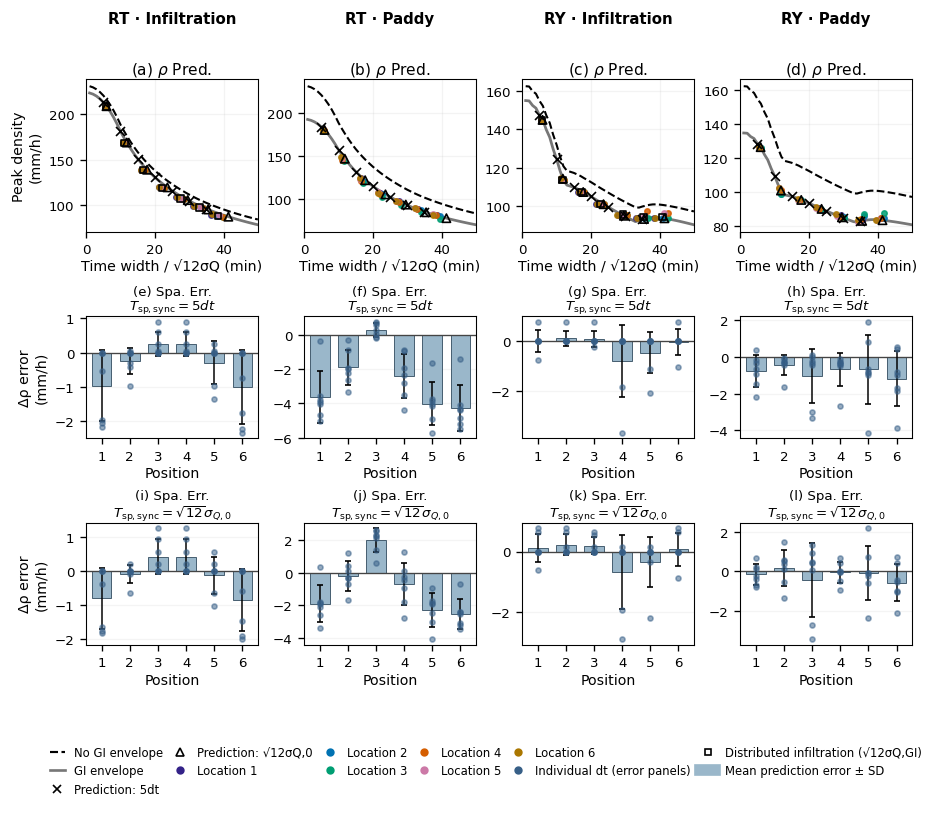

Combined Step 4 figure exported to: step4_spatial_equivalence_outputs


In [90]:
# Step 4 — Combined publication figure: 4 columns × 3 short rows, A4 portrait width.
# Original hydrology, scenario and envelope calculations (Cells 1–3) remain unchanged.
from matplotlib.lines import Line2D
S4_MECHS = [('infiltration', 'Infiltration'), ('paddy_storage', 'Paddy')]
S4_MARKERS = ['#332288', '#0072B2', '#009E73', '#D55E00', '#CC79A7', '#AA7700']

# Error summary: do not mix methods or rainfalls in the averages.
loc_errors = step4_prediction_df[
    step4_prediction_df.placement.str.startswith(('localized_', 'pattern_shift_'))
].copy()
loc_errors['position'] = loc_errors.placement.str.extract(r'(\d+)$').astype(int)
step4_error_summary = (
    loc_errors.groupby(['rainfall', 'mechanism', 'method', 'position'])
    .prediction_error_mm_h.agg(mean='mean', sd='std', min='min', max='max', n='size')
    .reset_index()
)
step4_error_summary.to_csv(S4_DIR / 'step4_error_summary_by_location.csv', index=False)

# One A4-portrait-compatible figure, 190 mm wide and SHORT (168 mm).
# Four columns are: RT infiltration, RT paddy, RY infiltration, RY paddy.
# Rows: envelopes and outcomes; planning Tsp,sync=5dt; planning Tsp,sync=sqrt(12)*sigmaQ,0.
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 8.5, 'axes.titlesize': 9.2, 'axes.labelsize': 8.5,
    'xtick.labelsize': 8.0, 'ytick.labelsize': 8.0, 'legend.fontsize': 8.0,
})
S4_FIG_W_MM, S4_FIG_H_MM = 190, 176
fig, axes = plt.subplots(
    3, 4, figsize=(S4_FIG_W_MM / 25.4, S4_FIG_H_MM / 25.4),
    gridspec_kw={'height_ratios': [1.25, 1, 1]},
)
fig.subplots_adjust(left=.075, right=.995, top=.885, bottom=.205, wspace=.27, hspace=.64)
# Shared headings for each column (all three rows).
column_headings = ['RT · Infiltration', 'RT · Paddy', 'RY · Infiltration', 'RY · Paddy']
for col, heading in enumerate(column_headings):
    pos = axes[0, col].get_position()
    fig.text((pos.x0 + pos.x1)/2, .958, heading, ha='center', va='center',
             fontsize=9.0, fontweight='bold')
columns = [(rn, mech, lab) for rn in S4_RAIN for mech, lab in S4_MECHS]
for col, (rain_name, mech, tech_label) in enumerate(columns):
    ax = axes[0, col]
    w, base_e = s4_env_curves[rain_name, 'baseline']
    _, gi_e = s4_env_curves[rain_name, mech]
    ax.plot(w, base_e, '--', color='black', linewidth=1.25)
    ax.plot(w, gi_e, '-', color='#777777', linewidth=1.65)
    part = step4_gi_df.query('rainfall==@rain_name and mechanism==@mech')
    locations = ([f'localized_subbasin_{i}' for i in range(1, 7)] if mech=='infiltration'
                 else [f'pattern_shift_{i}' for i in range(1, 7)])
    for j, loc in enumerate(locations):
        group = part[part.placement == loc].sort_values('dt_min')
        ax.scatter(group.weighted_sqrt12sigma_min, group.peak_mm_h,
                   color=S4_MARKERS[j], s=10, alpha=.85, zorder=3)
    pred = step4_prediction_df.query('rainfall==@rain_name and mechanism==@mech')
    for method, marker in [('5dt', 'x'), ('sqrt12sigma0', '^')]:
        subset = pred[pred.method==method].drop_duplicates(['dt_min']).sort_values('dt_min')
        ax.scatter(subset.planning_time_min, subset.envelopeGI_mm_h,
                   marker=marker, s=29 if marker=='x' else 25,
                   linewidths=1.0, facecolors='none' if marker=='^' else 'black',
                   edgecolors='black' if marker=='^' else None,
                   color='black', zorder=5)
    if mech == 'infiltration':
        dist = part[part.placement=='distributed_10pct_each']
        ax.scatter(dist.weighted_sqrt12sigma_min, dist.peak_mm_h,
                   marker='s', facecolors='none', edgecolors='black', s=15, zorder=4)
    ax.set_title(f'({chr(97+col)}) ' + r'$\rho$ Pred.', pad=3)
    ax.set_xlim(0, 50)
    ax.grid(alpha=.14)
    ax.set_xlabel('Time width / √12σQ (min)', labelpad=2)
    if col == 0:
        ax.set_ylabel('Peak density\n(mm/h)')
    for row_idx, method in [(1, '5dt'), (2, 'sqrt12sigma0')]:
        ae = axes[row_idx, col]
        sums = step4_error_summary.query(
            'rainfall==@rain_name and mechanism==@mech and method==@method'
        ).sort_values('position')
        dots = loc_errors.query(
            'rainfall==@rain_name and mechanism==@mech and method==@method'
        )
        ae.bar(sums.position, sums['mean'], width=.7,
               color='#9AB7CA', edgecolor='#304A5D', linewidth=.5, zorder=2)
        ae.errorbar(sums.position, sums['mean'],
                    yerr=sums.sd.fillna(0), fmt='none', color='black',
                    capsize=2.0, linewidth=.9, zorder=4)
        for dt in S4_DTS:
            dat = dots[dots.dt_min==dt].sort_values('position')
            ae.scatter(dat.position, dat.prediction_error_mm_h,
                       color='#375F87', s=9, alpha=.52, zorder=5)
        ae.axhline(0, color='#444444', lw=.8)
        ae.set_xticks(range(1,7))
        ae.set_xlim(.45,6.55)
        panel_letter = chr(97 + 4*row_idx + col)
        time_label = (r'$T_{\mathrm{sp,sync}}=5dt$' if row_idx == 1
                      else r'$T_{\mathrm{sp,sync}}=\sqrt{12}\sigma_{Q,0}$')
        ae.set_title(f'({panel_letter}) Spa. Err.\n' + time_label,
                     fontsize=8.0, pad=2, linespacing=1.05)
        ae.grid(axis='y', alpha=.13)
        ae.set_xlabel('Position', labelpad=2)
        if col == 0:
            ae.set_ylabel('Δρ error\n(mm/h)')
# Shared legend under all four columns, avoiding tiny in-panel legends.
handles = [
    Line2D([0],[0],color='black',linestyle='--',lw=1.3,label='No GI envelope'),
    Line2D([0],[0],color='#777777',lw=1.6,label='GI envelope'),
    Line2D([0],[0],marker='x',color='black',linestyle='None',markersize=5,label='Prediction: 5dt'),
    Line2D([0],[0],marker='^',markerfacecolor='none',markeredgecolor='black',
           linestyle='None',markersize=5,label='Prediction: √12σQ,0'),
    *[Line2D([0],[0],marker='o',color=S4_MARKERS[j],linestyle='None',markersize=4,
             label=f'Location {j+1}') for j in range(6)],
    Line2D([0],[0],marker='o',color='#375F87',linestyle='None',markersize=4,
           label='Individual dt (error panels)'),
    Line2D([0],[0],marker='s',markerfacecolor='none',markeredgecolor='black',
           linestyle='None',markersize=4,label='Distributed infiltration (√12σQ,GI)'),
    Line2D([0],[0],color='#9AB7CA',lw=7,label='Mean prediction error ± SD'),
]
fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(.52, .01),
           ncol=6, frameon=False, fontsize=7.0, columnspacing=.8, handlelength=1.3)
fig.savefig(S4_DIR / 'Step4_combined_column_headers.pdf', bbox_inches='tight')
fig.savefig(S4_DIR / 'Step4_combined_column_headers.png',
            dpi=300, bbox_inches='tight')
plt.show()
print('Combined Step 4 figure exported to:', S4_DIR)


In [86]:
# Step 4 supplementary numerical comparison: □ distributed placement versus △ prediction
# Uses step4_prediction_df and step4_gi_df from Step 4 Cells 2–3; hydrology unchanged.
import numpy as np
import pandas as pd

compare_sq_tri = step4_prediction_df.loc[
    (step4_prediction_df['mechanism'] == 'infiltration')
    & (step4_prediction_df['placement'] == 'distributed_10pct_each')
    & (step4_prediction_df['method'] == 'sqrt12sigma0')
].copy()
assert len(compare_sq_tri) == len(S4_RAIN) * len(S4_DTS), (
    'Unexpected number of distributed-infiltration comparisons'
)

# Difference in the Y coordinates of square and triangle in the top-row panels.
compare_sq_tri['square_minus_triangle_peak_mm_h'] = (
    compare_sq_tri['peakGI_actual_mm_h'] - compare_sq_tri['envelopeGI_mm_h']
)
compare_sq_tri['peak_difference_pct_of_triangle'] = np.where(
    compare_sq_tri['envelopeGI_mm_h'].abs() > 1.e-12,
    100 * compare_sq_tri['square_minus_triangle_peak_mm_h'] /
    compare_sq_tri['envelopeGI_mm_h'], np.nan
)
# For the research question about reduction rather than peak density.
compare_sq_tri['actual_minus_predicted_reduction_mm_h'] = (
    compare_sq_tri['actual_delta_mm_h'] - compare_sq_tri['predicted_delta_mm_h']
)
compare_sq_tri['reduction_error_pct_of_prediction'] = np.where(
    compare_sq_tri['predicted_delta_mm_h'].abs() > 1.e-12,
    100 * compare_sq_tri['actual_minus_predicted_reduction_mm_h'] /
    compare_sq_tri['predicted_delta_mm_h'], np.nan
)

out_cols = [
    'rainfall', 'dt_min', 'planning_time_min', 'actual_spread_min',
    'envelopeGI_mm_h', 'peakGI_actual_mm_h',
    'square_minus_triangle_peak_mm_h', 'peak_difference_pct_of_triangle',
    'predicted_delta_mm_h', 'actual_delta_mm_h',
    'actual_minus_predicted_reduction_mm_h', 'reduction_error_pct_of_prediction'
]
comparison_detail = compare_sq_tri[out_cols].sort_values(['rainfall', 'dt_min'])
comparison_detail.to_csv(S4_DIR / 'step4_square_vs_triangle_by_dt.csv', index=False)

comparison_summary = compare_sq_tri.groupby('rainfall', as_index=False).agg(
    n_dt=('dt_min', 'size'),
    mean_square_minus_triangle_mm_h=('square_minus_triangle_peak_mm_h', 'mean'),
    mae_square_minus_triangle_mm_h=('square_minus_triangle_peak_mm_h', lambda v: np.mean(np.abs(v))),
    max_abs_square_minus_triangle_mm_h=('square_minus_triangle_peak_mm_h', lambda v: np.max(np.abs(v))),
    mean_reduction_error_mm_h=('actual_minus_predicted_reduction_mm_h', 'mean'),
    mae_reduction_error_mm_h=('actual_minus_predicted_reduction_mm_h', lambda v: np.mean(np.abs(v))),
    max_abs_reduction_error_mm_h=('actual_minus_predicted_reduction_mm_h', lambda v: np.max(np.abs(v)))
)
comparison_summary.to_csv(S4_DIR / 'step4_square_vs_triangle_summary.csv', index=False)

print('□ actual GI peak − △ predicted GI peak (positive = □ lies ABOVE △)')
print(comparison_detail.round(3).to_string(index=False))
print('\nSummary by rainfall, dt = 1–7:')
print(comparison_summary.round(3).to_string(index=False))
print('\nCSV output:', S4_DIR.resolve())

□ actual GI peak − △ predicted GI peak (positive = □ lies ABOVE △)
rainfall  dt_min  planning_time_min  actual_spread_min  envelopeGI_mm_h  peakGI_actual_mm_h  square_minus_triangle_peak_mm_h  peak_difference_pct_of_triangle  predicted_delta_mm_h  actual_delta_mm_h  actual_minus_predicted_reduction_mm_h  reduction_error_pct_of_prediction
      RT       1              5.916              5.748          209.187             208.790                           -0.397                           -0.190                 7.500              7.500                                 -0.000                             -0.000
      RT       2             11.832             11.161          168.946             168.298                           -0.647                           -0.383                 7.500              7.500                                 -0.000                             -0.000
      RT       3             17.748             16.598          138.876             138.330                       